In [1]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

CUDA available: True
GPU: NVIDIA L4


In [2]:
import time

start = time.perf_counter()

result = sum(range(100000))

elapsed = time.perf_counter() - start

print(f"Execution time: {elapsed:.4f} seconds")

Execution time: 0.0023 seconds


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Hacks/AI-NETRA")
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Folder exists:", PROJECT_ROOT.exists())

Project folder: /content/drive/MyDrive/Hacks/AI-NETRA
Folder exists: True


In [5]:
folders = ["datasets", "models", "checkpoints", "experiments", "logs"]

for folder in folders:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


In [6]:
test_file = PROJECT_ROOT / "storage_test.txt"

test_file.write_text("AI NETRA storage test successful")

print(test_file.read_text())

AI NETRA storage test successful


In [7]:
from pathlib import Path

test_file = Path("/content/drive/MyDrive/Hacks/AI-NETRA/storage_test.txt")

print("File exists:", test_file.exists())
print("Content:", test_file.read_text())

File exists: True
Content: AI NETRA storage test successful


In [8]:
import cv2

print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


In [11]:
try:
    import ultralytics
    print("Ultralytics version:", ultralytics.__version__)
except ImportError:
    print("Ultralytics is not installed")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.208


In [12]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")
print("Model classes:", len(model.names))
print("Person class:", model.names[0])

YOLO model loaded successfully!
Model classes: 80
Person class: person


In [13]:
import shutil

model_source = "yolo11n.pt"
model_destination = PROJECT_ROOT / "models" / "yolo11n.pt"

shutil.copy2(model_source, model_destination)

print("Model saved:", model_destination)
print("File size (MB):", round(model_destination.stat().st_size / (1024 * 1024), 2))

Model saved: /content/drive/MyDrive/Hacks/AI-NETRA/models/yolo11n.pt
File size (MB): 5.35



image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 10.0ms
Speed: 300.1ms preprocess, 10.0ms inference, 99.2ms postprocess per image at shape (1, 3, 640, 480)
bus: 0.94
person: 0.89
person: 0.88
person: 0.86
person: 0.62


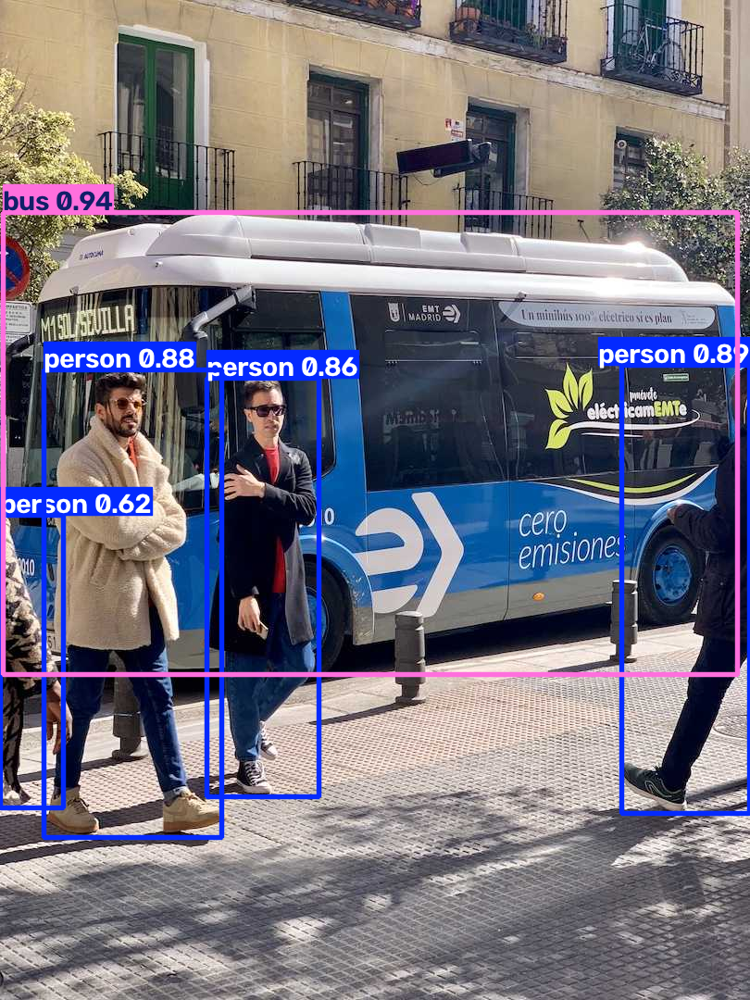

In [14]:
from ultralytics import YOLO

# Load the model from persistent storage
model = YOLO(str(PROJECT_ROOT / "models" / "yolo11n.pt"))

# Run inference on an Ultralytics sample image
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    device=0,
    conf=0.25,
    verbose=True
)

# Display detected objects
for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    print(f"{model.names[class_id]}: {confidence:.2f}")

# Display annotated image
from IPython.display import display
from PIL import Image

display(Image.fromarray(results[0].plot()[..., ::-1]))

In [15]:
for i, box in enumerate(results[0].boxes):
    class_id = int(box.cls[0])

    if model.names[class_id] == "person":
        coordinates = box.xyxy[0].tolist()
        confidence = float(box.conf[0])

        print(f"Person {i + 1}")
        print(f"  Bounding Box: {[round(x, 1) for x in coordinates]}")
        print(f"  Confidence: {confidence:.2f}")

Person 2
  Bounding Box: [671.0, 394.8, 809.8, 878.7]
  Confidence: 0.89
Person 3
  Bounding Box: [47.4, 399.6, 239.3, 904.2]
  Confidence: 0.88
Person 4
  Bounding Box: [223.1, 408.7, 344.5, 860.4]
  Confidence: 0.86
Person 5
  Bounding Box: [0.0, 556.1, 68.9, 872.4]
  Confidence: 0.62


In [16]:
box = results[0].boxes[1]

x1, y1, x2, y2 = box.xyxy[0].tolist()

width = x2 - x1
height = y2 - y1

print(f"Width: {width:.1f} pixels")
print(f"Height: {height:.1f} pixels")
print(f"Area: {width * height:.1f} square pixels")

Width: 138.8 pixels
Height: 483.9 pixels
Area: 67153.0 square pixels


In [17]:
# Select the same bounding box
box = results[0].boxes[1]

x1, y1, x2, y2 = box.xyxy[0].tolist()

center_x = (x1 + x2) / 2
center_y = (y1 + y2) / 2

print(f"Center X: {center_x:.1f} pixels")
print(f"Center Y: {center_y:.1f} pixels")

Center X: 740.4 pixels
Center Y: 636.8 pixels


In [18]:
# Run inference for the person class only (class ID = 0)
person_results = model.predict(
    source="bus.jpg",
    classes=[0],
    conf=0.25,
    device=0,
    verbose=False
)

print("Total people detected:", len(person_results[0].boxes))

for i, box in enumerate(person_results[0].boxes, start=1):
    confidence = float(box.conf[0])
    print(f"Person {i}: Confidence = {confidence:.2f}")

Total people detected: 4
Person 1: Confidence = 0.89
Person 2: Confidence = 0.88
Person 3: Confidence = 0.86
Person 4: Confidence = 0.62


Annotated image saved: /content/drive/MyDrive/Hacks/AI-NETRA/experiments/person_detection_01.jpg


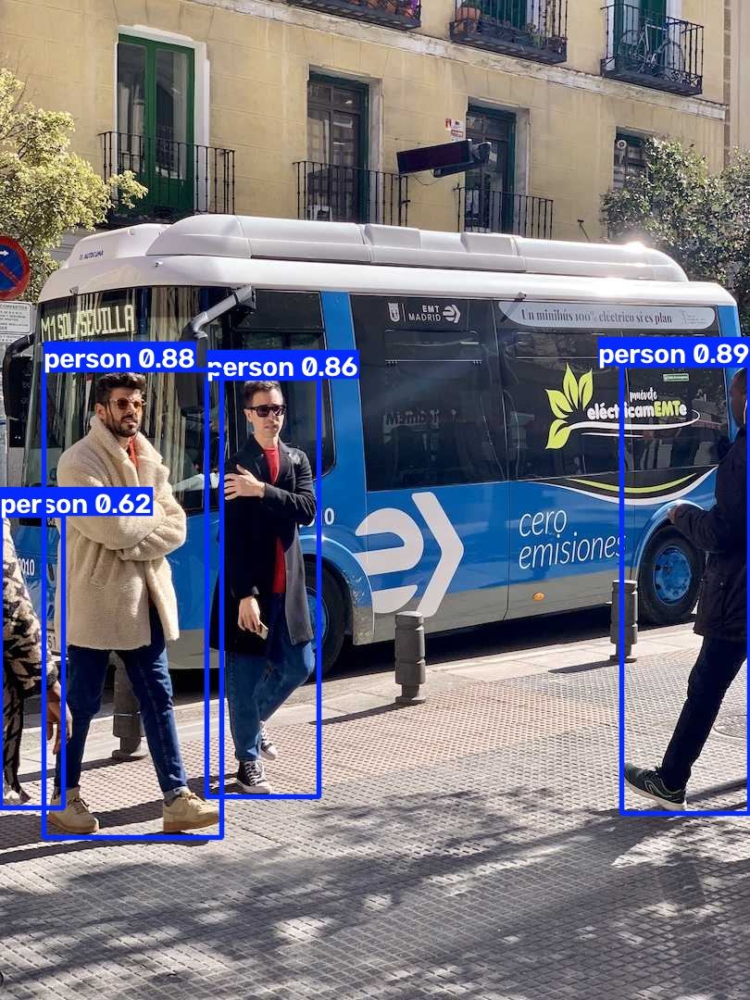

In [19]:
import cv2
from IPython.display import display, Image

# Generate annotated image
annotated_image = person_results[0].plot()

# Save to Google Drive
output_path = PROJECT_ROOT / "experiments" / "person_detection_01.jpg"

cv2.imwrite(str(output_path), annotated_image)

print("Annotated image saved:", output_path)

# Display the saved image
display(Image(filename=str(output_path)))

Frame extracted successfully!
Original frame shape: (1080, 810, 3)


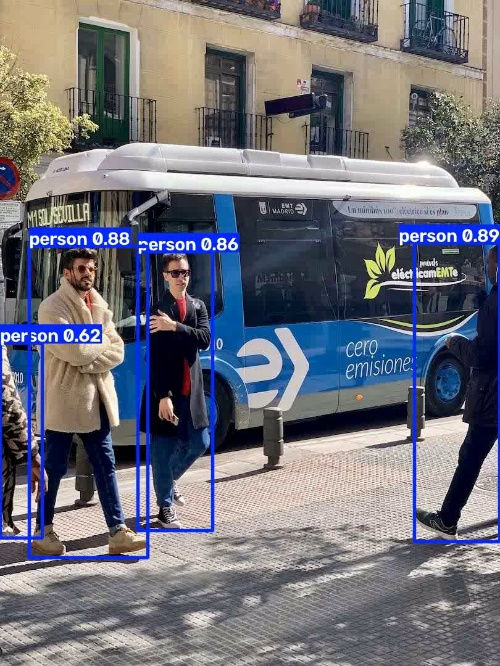

In [23]:
import cv2
from IPython.display import display, Image

cap = cv2.VideoCapture(str(video_path))

success, frame = cap.read()

if success:
    print("Frame extracted successfully!")
    print("Original frame shape:", frame.shape)

    # Display a smaller preview without changing the original frame
    preview_width = min(500, frame.shape[1])
    preview_height = int(frame.shape[0] * preview_width / frame.shape[1])

    preview = cv2.resize(frame, (preview_width, preview_height))

    _, buffer = cv2.imencode(".jpg", preview)
    display(Image(data=buffer.tobytes()))
else:
    print("Failed to read frame")

cap.release()

In [20]:
import cv2

print("OpenCV version:", cv2.__version__)
print("VideoCapture available:", hasattr(cv2, "VideoCapture"))
print("VideoWriter available:", hasattr(cv2, "VideoWriter"))

OpenCV version: 5.0.0
VideoCapture available: True
VideoWriter available: True


In [21]:
import cv2

# Load our annotated image
image = cv2.imread(str(output_path))

height, width = image.shape[:2]

# Create a 5-second video at 10 FPS
video_path = PROJECT_ROOT / "experiments" / "test_video.mp4"

writer = cv2.VideoWriter(
    str(video_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    10,
    (width, height)
)

for _ in range(50):
    writer.write(image)

writer.release()

# Verify that OpenCV can read the video
cap = cv2.VideoCapture(str(video_path))

print("Video opened:", cap.isOpened())
print("Total frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv2.CAP_PROP_FPS))

cap.release()

Video opened: True
Total frames: 50
FPS: 10.0


In [24]:
import cv2

cap = cv2.VideoCapture(str(video_path))
success, frame = cap.read()
cap.release()

if success:
    detections = model.predict(
        source=frame,
        classes=[0],
        conf=0.25,
        device=0,
        verbose=False
    )

    print("People detected:", len(detections[0].boxes))
else:
    print("Unable to extract video frame")

People detected: 4


In [26]:
from IPython.display import display, HTML
from base64 import b64encode

with open(video_path, "rb") as f:
    video_data = b64encode(f.read()).decode()

display(HTML(f"""
<video width="400" controls>
    <source src="data:video/mp4;base64,{video_data}" type="video/mp4">
    Your browser does not support video playback.
</video>
"""))

In [27]:
import subprocess

compatible_video = PROJECT_ROOT / "experiments" / "test_video_h264.mp4"

result = subprocess.run(
    [
        "ffmpeg", "-y",
        "-i", str(video_path),
        "-c:v", "libx264",
        "-pix_fmt", "yuv420p",
        str(compatible_video)
    ],
    capture_output=True,
    text=True
)

print("Conversion successful:", result.returncode == 0)

if result.returncode != 0:
    print(result.stderr[-1000:])

Conversion successful: True


In [28]:
from IPython.display import display, HTML
from base64 import b64encode

with open(compatible_video, "rb") as f:
    video_data = b64encode(f.read()).decode("utf-8")

display(HTML(f"""
<video width="400" controls playsinline>
    <source src="data:video/mp4;base64,{video_data}" type="video/mp4">
    Video playback is not supported.
</video>
"""))

In [29]:
import urllib.request
from pathlib import Path

video_url = "https://github.com/intel-iot-devkit/sample-videos/raw/master/people-detection.mp4"

real_video_path = PROJECT_ROOT / "datasets" / "people_detection.mp4"

urllib.request.urlretrieve(video_url, real_video_path)

print("Video downloaded successfully!")
print("Size (MB):", round(real_video_path.stat().st_size / (1024 * 1024), 2))

Video downloaded successfully!
Size (MB): 5.23


In [30]:
import cv2

cap = cv2.VideoCapture(str(real_video_path))

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("Video opened:", cap.isOpened())
print("Resolution:", width, "x", height)
print("FPS:", fps)
print("Total frames:", total_frames)
print("Duration:", round(total_frames / fps, 2) if fps > 0 else "Unknown", "seconds")

cap.release()

Video opened: True
Resolution: 768 x 432
FPS: 12.0
Total frames: 596
Duration: 49.67 seconds


In [31]:
from IPython.display import display, HTML
from base64 import b64encode

with open(real_video_path, "rb") as f:
    video_data = b64encode(f.read()).decode("utf-8")

display(HTML(f"""
<video width="400" controls playsinline>
    <source src="data:video/mp4;base64,{video_data}" type="video/mp4">
    Your browser does not support video playback.
</video>
"""))

In [32]:
import cv2

cap = cv2.VideoCapture(str(real_video_path))

fps = cap.get(cv2.CAP_PROP_FPS)
frame_number = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    # Analyze approximately one frame per second
    if frame_number % int(fps) == 0:
        results_video = model.predict(
            source=frame,
            classes=[0],
            conf=0.25,
            device=0,
            verbose=False
        )

        people_count = len(results_video[0].boxes)

        timestamp = frame_number / fps

        print(f"Time: {timestamp:.1f}s | People detected: {people_count}")

    frame_number += 1

cap.release()

Time: 0.0s | People detected: 0
Time: 1.0s | People detected: 0
Time: 2.0s | People detected: 1
Time: 3.0s | People detected: 1
Time: 4.0s | People detected: 1
Time: 5.0s | People detected: 1
Time: 6.0s | People detected: 1
Time: 7.0s | People detected: 0
Time: 8.0s | People detected: 0
Time: 9.0s | People detected: 0
Time: 10.0s | People detected: 0
Time: 11.0s | People detected: 0
Time: 12.0s | People detected: 0
Time: 13.0s | People detected: 0
Time: 14.0s | People detected: 0
Time: 15.0s | People detected: 1
Time: 16.0s | People detected: 2
Time: 17.0s | People detected: 2
Time: 18.0s | People detected: 2
Time: 19.0s | People detected: 2
Time: 20.0s | People detected: 2
Time: 21.0s | People detected: 0
Time: 22.0s | People detected: 0
Time: 23.0s | People detected: 0
Time: 24.0s | People detected: 0
Time: 25.0s | People detected: 0
Time: 26.0s | People detected: 0
Time: 27.0s | People detected: 0
Time: 28.0s | People detected: 0
Time: 29.0s | People detected: 2
Time: 30.0s | People

In [33]:
import cv2

cap = cv2.VideoCapture(str(real_video_path))

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

annotated_video_path = PROJECT_ROOT / "experiments" / "people_detection_annotated.mp4"

writer = cv2.VideoWriter(
    str(annotated_video_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

processed_frames = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    results_frame = model.predict(
        source=frame,
        classes=[0],
        conf=0.25,
        device=0,
        verbose=False
    )

    annotated_frame = results_frame[0].plot()
    writer.write(annotated_frame)

    processed_frames += 1

cap.release()
writer.release()

print("Frames processed:", processed_frames)
print("Annotated video saved:", annotated_video_path)

Frames processed: 596
Annotated video saved: /content/drive/MyDrive/Hacks/AI-NETRA/experiments/people_detection_annotated.mp4


In [34]:
import subprocess

final_video_path = PROJECT_ROOT / "experiments" / "people_detection_final.mp4"

result = subprocess.run(
    [
        "ffmpeg", "-y",
        "-i", str(annotated_video_path),
        "-c:v", "libx264",
        "-preset", "fast",
        "-crf", "23",
        "-pix_fmt", "yuv420p",
        str(final_video_path)
    ],
    capture_output=True,
    text=True
)

print("Conversion successful:", result.returncode == 0)

if result.returncode == 0:
    print("Video size (MB):", round(final_video_path.stat().st_size / (1024 * 1024), 2))
else:
    print(result.stderr[-1000:])

Conversion successful: True
Video size (MB): 1.9


In [35]:
from IPython.display import display, HTML
from base64 import b64encode

with open(final_video_path, "rb") as f:
    video_data = b64encode(f.read()).decode("utf-8")

display(HTML(f"""
<video width="400" controls playsinline>
    <source src="data:video/mp4;base64,{video_data}" type="video/mp4">
    Video playback is not supported.
</video>
"""))

In [36]:
from ultralytics import YOLO

tracker_model = YOLO(str(PROJECT_ROOT / "models" / "yolo11n.pt"))

tracking_results = tracker_model.track(
    source=str(real_video_path),
    tracker="bytetrack.yaml",
    classes=[0],
    conf=0.25,
    device=0,
    persist=True,
    stream=True,
    verbose=False
)

unique_ids = set()
frames_processed = 0

for result in tracking_results:
    frames_processed += 1

    if result.boxes is not None and result.boxes.id is not None:
        ids = result.boxes.id.int().cpu().tolist()
        unique_ids.update(ids)

print("Frames processed:", frames_processed)
print("Unique tracking IDs:", len(unique_ids))
print("Tracking IDs:", sorted(unique_ids))

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 180ms
Prepared 1 package in 21ms
Installed 1 package in 3ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Frames processed: 596
Unique tracking IDs: 8
Tracking IDs: [2, 3, 4, 7, 8, 10, 13, 15]


In [37]:
import cv2

cap = cv2.VideoCapture(str(real_video_path))

tracker_model = YOLO(
    str(PROJECT_ROOT / "models" / "yolo11n.pt")
)

frame_number = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    result = tracker_model.track(
        frame,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.25,
        device=0,
        persist=True,
        verbose=False
    )[0]

    if frame_number % 60 == 0:
        ids = []

        if result.boxes.id is not None:
            ids = result.boxes.id.int().cpu().tolist()

        print(f"Frame {frame_number}: Tracking IDs = {ids}")

    frame_number += 1

cap.release()

Frame 0: Tracking IDs = []
Frame 60: Tracking IDs = [2]
Frame 120: Tracking IDs = []
Frame 180: Tracking IDs = []
Frame 240: Tracking IDs = [3, 4]
Frame 300: Tracking IDs = []
Frame 360: Tracking IDs = [7, 10, 8]
Frame 420: Tracking IDs = []
Frame 480: Tracking IDs = []
Frame 540: Tracking IDs = [15]


In [38]:
import cv2
from ultralytics import YOLO

tracker_model = YOLO(str(PROJECT_ROOT / "models" / "yolo11n.pt"))

tracked_video_path = PROJECT_ROOT / "experiments" / "people_tracking.mp4"

cap = cv2.VideoCapture(str(real_video_path))

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

writer = cv2.VideoWriter(
    str(tracked_video_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

frames_processed = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    result = tracker_model.track(
        source=frame,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.25,
        device=0,
        persist=True,
        verbose=False
    )[0]

    annotated_frame = result.plot()
    writer.write(annotated_frame)

    frames_processed += 1

cap.release()
writer.release()

print("Frames processed:", frames_processed)
print("Tracked video saved:", tracked_video_path)

Frames processed: 596
Tracked video saved: /content/drive/MyDrive/Hacks/AI-NETRA/experiments/people_tracking.mp4


In [39]:
import subprocess

tracking_final_path = PROJECT_ROOT / "experiments" / "people_tracking_final.mp4"

result = subprocess.run(
    [
        "ffmpeg", "-y",
        "-i", str(tracked_video_path),
        "-c:v", "libx264",
        "-preset", "fast",
        "-crf", "23",
        "-pix_fmt", "yuv420p",
        str(tracking_final_path)
    ],
    capture_output=True,
    text=True
)

print("Conversion successful:", result.returncode == 0)

if result.returncode == 0:
    print("Video size (MB):", round(tracking_final_path.stat().st_size / (1024 * 1024), 2))
else:
    print(result.stderr[-1000:])

Conversion successful: True
Video size (MB): 1.94


In [40]:
from IPython.display import display, HTML
from base64 import b64encode

with open(tracking_final_path, "rb") as f:
    video_data = b64encode(f.read()).decode("utf-8")

display(HTML(f"""
<video width="400" controls playsinline>
    <source src="data:video/mp4;base64,{video_data}" type="video/mp4">
    Video playback is not supported.
</video>
"""))

In [41]:
import json
from datetime import datetime, timezone

experiment = {
    "experiment_id": "EXP-001",
    "project": "AI-NETRA",
    "model": "YOLO11n",
    "tracker": "ByteTrack",
    "video": "people_detection.mp4",
    "frames_processed": 596,
    "tracking_ids_observed": 8,
    "observations": {
        "id_consistency": "Visually consistent while subjects remained visible",
        "re_identification": "Not evaluated",
        "tracking_accuracy": "Not quantitatively evaluated"
    },
    "timestamp": datetime.now(timezone.utc).isoformat()
}

experiment_path = PROJECT_ROOT / "experiments" / "EXP-001.json"

with open(experiment_path, "w") as f:
    json.dump(experiment, f, indent=4)

print("Experiment saved:", experiment_path)

Experiment saved: /content/drive/MyDrive/Hacks/AI-NETRA/experiments/EXP-001.json


In [42]:
flood_video_dir = PROJECT_ROOT / "datasets" / "flood_videos"

flood_video_dir.mkdir(parents=True, exist_ok=True)

print("Flood video directory:", flood_video_dir)
print("Directory exists:", flood_video_dir.exists())

Flood video directory: /content/drive/MyDrive/Hacks/AI-NETRA/datasets/flood_videos
Directory exists: True


In [43]:
from pathlib import Path

flood_video_dir = PROJECT_ROOT / "datasets" / "flood_videos"

videos = sorted(flood_video_dir.glob("*.mp4"))

print(f"Total videos found: {len(videos)}\n")

for i, video in enumerate(videos, start=1):
    size_mb = video.stat().st_size / (1024 * 1024)
    print(f"{i}. {video.name} — {size_mb:.2f} MB")

Total videos found: 5

1. 2022111805.mp4 — 93.76 MB
2. 2023020103.mp4 — 1.55 MB
3. 2023020104.mp4 — 5.26 MB
4. 2023020108.mp4 — 17.03 MB
5. 2023033002.mp4 — 34.08 MB


In [44]:
import cv2

for video in videos:
    cap = cv2.VideoCapture(str(video))

    if not cap.isOpened():
        print(f"{video.name}: Unable to open")
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = frames / fps if fps > 0 else 0

    print(
        f"{video.name} | "
        f"{width}x{height} | "
        f"{fps:.1f} FPS | "
        f"{duration:.1f} sec | "
        f"{frames} frames"
    )

    cap.release()

2022111805.mp4 | 1080x1920 | 30.0 FPS | 60.1 sec | 1804 frames
2023020103.mp4 | 480x854 | 30.0 FPS | 9.3 sec | 279 frames
2023020104.mp4 | 1080x1920 | 30.0 FPS | 14.0 sec | 419 frames
2023020108.mp4 | 1280x720 | 30.0 FPS | 12.0 sec | 361 frames
2023033002.mp4 | 1080x1920 | 30.0 FPS | 21.7 sec | 650 frames


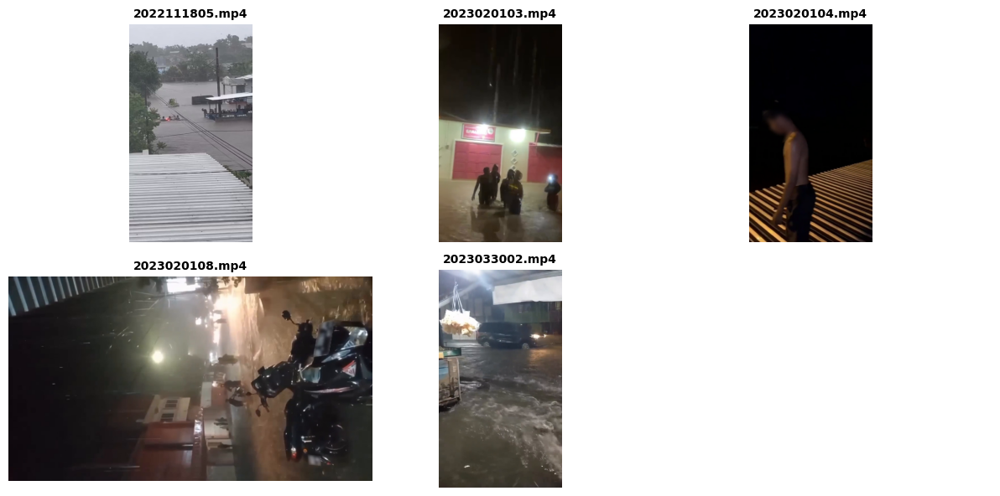

In [46]:
import cv2
import matplotlib.pyplot as plt

# Create a compact grid: 2 rows × 3 columns
fig, axes = plt.subplots(2, 3, figsize=(12, 6))

axes = axes.flatten()

for i, video in enumerate(videos):

    cap = cv2.VideoCapture(str(video))

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Extract middle frame
    cap.set(cv2.CAP_PROP_POS_FRAMES, total_frames // 2)

    success, frame = cap.read()
    cap.release()

    if success:
        # Convert OpenCV BGR to RGB
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Display frame
        axes[i].imshow(frame_rgb)
        axes[i].set_title(video.name, fontsize=10, fontweight="bold")
    else:
        axes[i].text(
            0.5, 0.5, "Frame unavailable",
            ha="center", va="center"
        )

    axes[i].axis("off")

# Hide unused sixth position
for j in range(len(videos), len(axes)):
    axes[j].axis("off")

plt.tight_layout(pad=1)
plt.show()

In [47]:
import cv2
from ultralytics import YOLO

flood_video = flood_video_dir / "2023020103.mp4"

cap = cv2.VideoCapture(str(flood_video))

fps = cap.get(cv2.CAP_PROP_FPS)
frame_number = 0
total_detections = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    # Analyze one frame per second
    if frame_number % int(fps) == 0:

        result = model.predict(
            source=frame,
            classes=[0],
            conf=0.25,
            device=0,
            verbose=False
        )[0]

        count = len(result.boxes)
        total_detections += count

        print(
            f"Time: {frame_number / fps:.1f}s | "
            f"People detected: {count}"
        )

    frame_number += 1

cap.release()

print("\nTotal detection instances:", total_detections)

Time: 0.0s | People detected: 0
Time: 1.0s | People detected: 0
Time: 2.0s | People detected: 0
Time: 3.0s | People detected: 0
Time: 4.0s | People detected: 3
Time: 5.0s | People detected: 4
Time: 6.0s | People detected: 2
Time: 7.0s | People detected: 0
Time: 8.0s | People detected: 3
Time: 9.0s | People detected: 2

Total detection instances: 14


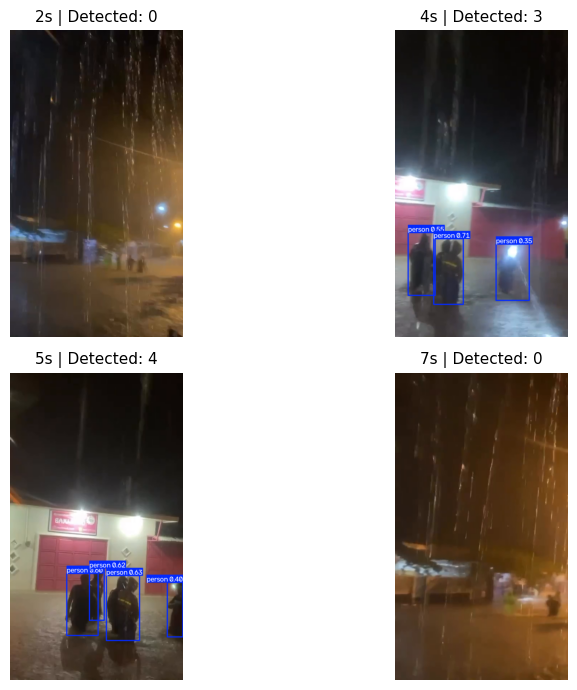

In [48]:
import cv2
import matplotlib.pyplot as plt

timestamps = [2, 4, 5, 7]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.flatten()

cap = cv2.VideoCapture(str(flood_video))

for i, timestamp in enumerate(timestamps):

    cap.set(cv2.CAP_PROP_POS_MSEC, timestamp * 1000)

    success, frame = cap.read()

    if not success:
        axes[i].axis("off")
        continue

    result = model.predict(
        source=frame,
        classes=[0],
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    annotated = result.plot()

    annotated_rgb = cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )

    axes[i].imshow(annotated_rgb)
    axes[i].set_title(
        f"{timestamp}s | Detected: {len(result.boxes)}",
        fontsize=11
    )
    axes[i].axis("off")

cap.release()

plt.tight_layout()
plt.show()

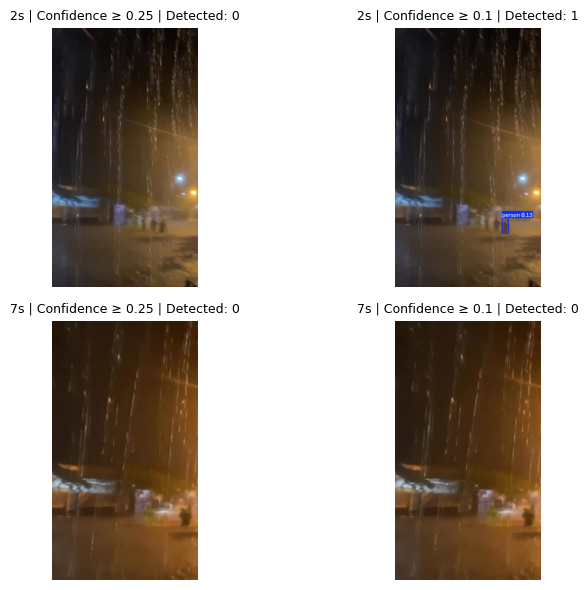

In [49]:
import cv2
import matplotlib.pyplot as plt

timestamps = [2, 7]
thresholds = [0.25, 0.10]

fig, axes = plt.subplots(2, 2, figsize=(9, 6))

cap = cv2.VideoCapture(str(flood_video))

for row, timestamp in enumerate(timestamps):
    cap.set(cv2.CAP_PROP_POS_MSEC, timestamp * 1000)
    success, frame = cap.read()

    if not success:
        continue

    for col, threshold in enumerate(thresholds):
        result = model.predict(
            source=frame,
            classes=[0],
            conf=threshold,
            device=0,
            verbose=False
        )[0]

        annotated = cv2.cvtColor(
            result.plot(), cv2.COLOR_BGR2RGB
        )

        axes[row, col].imshow(annotated)
        axes[row, col].set_title(
            f"{timestamp}s | Confidence ≥ {threshold} | "
            f"Detected: {len(result.boxes)}",
            fontsize=9
        )
        axes[row, col].axis("off")

cap.release()

plt.tight_layout()
plt.show()

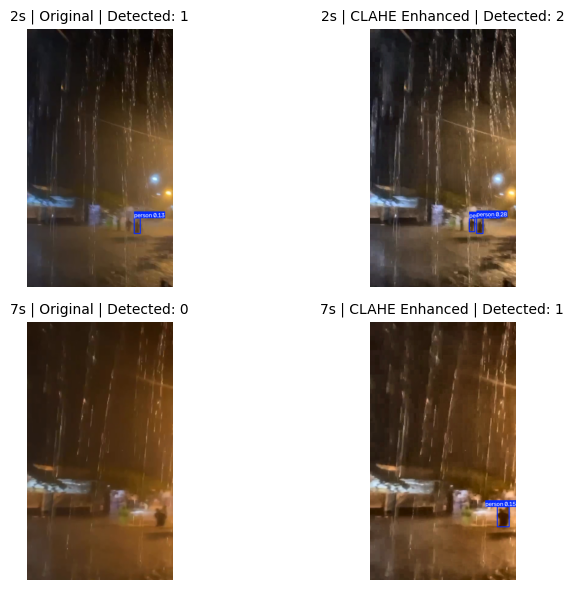

In [50]:
import cv2
import matplotlib.pyplot as plt

timestamps = [2, 7]

fig, axes = plt.subplots(2, 2, figsize=(9, 6))

cap = cv2.VideoCapture(str(flood_video))

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

for row, timestamp in enumerate(timestamps):

    cap.set(cv2.CAP_PROP_POS_MSEC, timestamp * 1000)
    success, frame = cap.read()

    if not success:
        continue

    # Enhance brightness and local contrast
    lab = cv2.cvtColor(frame, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    enhanced_l = clahe.apply(l)

    enhanced = cv2.cvtColor(
        cv2.merge((enhanced_l, a, b)),
        cv2.COLOR_LAB2BGR
    )

    for col, image in enumerate([frame, enhanced]):

        result = model.predict(
            source=image,
            classes=[0],
            conf=0.10,
            device=0,
            verbose=False
        )[0]

        annotated = cv2.cvtColor(
            result.plot(),
            cv2.COLOR_BGR2RGB
        )

        axes[row, col].imshow(annotated)

        label = "Original" if col == 0 else "CLAHE Enhanced"

        axes[row, col].set_title(
            f"{timestamp}s | {label} | Detected: {len(result.boxes)}",
            fontsize=10
        )

        axes[row, col].axis("off")

cap.release()

plt.tight_layout()
plt.show()

In [51]:
import cv2

cap = cv2.VideoCapture(str(flood_video))

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

for timestamp in [2, 7]:

    cap.set(cv2.CAP_PROP_POS_MSEC, timestamp * 1000)
    success, frame = cap.read()

    if not success:
        continue

    lab = cv2.cvtColor(frame, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    enhanced = cv2.cvtColor(
        cv2.merge((clahe.apply(l), a, b)),
        cv2.COLOR_LAB2BGR
    )

    print(f"\nTimestamp: {timestamp}s")

    for label, image in [
        ("Original", frame),
        ("CLAHE", enhanced)
    ]:
        result = model.predict(
            image,
            classes=[0],
            conf=0.10,
            device=0,
            verbose=False
        )[0]

        scores = [
            round(float(box.conf[0]), 3)
            for box in result.boxes
        ]

        print(f"{label}: {len(scores)} detections | Confidence: {scores}")

cap.release()


Timestamp: 2s
Original: 1 detections | Confidence: [0.13]
CLAHE: 2 detections | Confidence: [0.279, 0.144]

Timestamp: 7s
Original: 0 detections | Confidence: []
CLAHE: 1 detections | Confidence: [0.147]


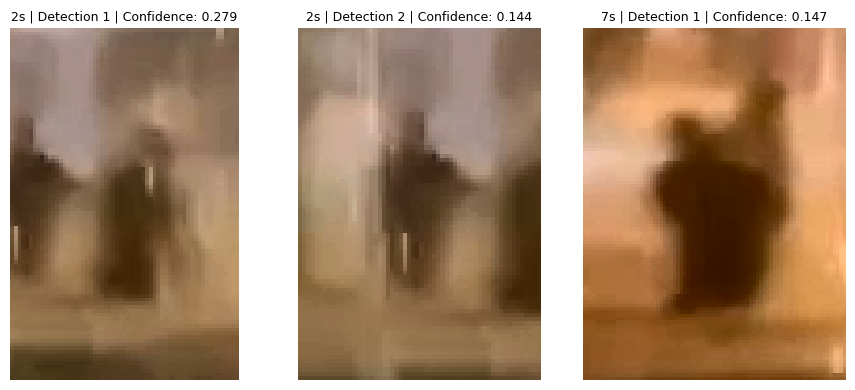

In [52]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(str(flood_video))

crops = []
labels = []

for timestamp in [2, 7]:
    cap.set(cv2.CAP_PROP_POS_MSEC, timestamp * 1000)
    success, frame = cap.read()

    if not success:
        continue

    lab = cv2.cvtColor(frame, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    enhanced = cv2.cvtColor(
        cv2.merge((clahe.apply(l), a, b)),
        cv2.COLOR_LAB2BGR
    )

    result = model.predict(
        enhanced,
        classes=[0],
        conf=0.10,
        device=0,
        verbose=False
    )[0]

    for i, box in enumerate(result.boxes):
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        crop = enhanced[
            max(0, y1 - 20):min(enhanced.shape[0], y2 + 20),
            max(0, x1 - 20):min(enhanced.shape[1], x2 + 20)
        ]

        if crop.size == 0:
            continue

        crops.append(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        labels.append(
            f"{timestamp}s | Detection {i+1} | "
            f"Confidence: {float(box.conf[0]):.3f}"
        )

cap.release()

if crops:
    fig, axes = plt.subplots(
        1, len(crops),
        figsize=(3 * len(crops), 4),
        squeeze=False
    )

    for ax, crop, label in zip(axes.flat, crops, labels):
        ax.imshow(crop)
        ax.set_title(label, fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No detections available for inspection.")

In [53]:
import json
from datetime import datetime, timezone

experiment = {
    "experiment_id": "EXP-002",
    "project": "AI-NETRA",
    "video": "2023020103.mp4",
    "model": "YOLO11n",
    "experiment": "Nighttime person detection with CLAHE",
    "confidence_threshold": 0.10,
    "results": {
        "2_seconds": {
            "original_detections": 1,
            "clahe_detections": 2,
            "original_confidence": [0.130],
            "clahe_confidence": [0.279, 0.144]
        },
        "7_seconds": {
            "original_detections": 0,
            "clahe_detections": 1,
            "clahe_confidence": [0.147]
        }
    },
    "visual_assessment": "Three likely person detections; not independently verified",
    "conclusion": "CLAHE is a candidate preprocessing technique requiring quantitative validation",
    "timestamp": datetime.now(timezone.utc).isoformat()
}

experiment_path = PROJECT_ROOT / "experiments" / "EXP-002.json"

with open(experiment_path, "w", encoding="utf-8") as f:
    json.dump(experiment, f, indent=4)

print("Experiment saved:", experiment_path)

Experiment saved: /content/drive/MyDrive/Hacks/AI-NETRA/experiments/EXP-002.json


In [54]:
import cv2

annotation_dir = PROJECT_ROOT / "datasets" / "annotations" / "EXP-002"
annotation_dir.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(flood_video))

timestamps = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

for timestamp in timestamps:
    cap.set(cv2.CAP_PROP_POS_MSEC, timestamp * 1000)

    success, frame = cap.read()

    if success:
        output = annotation_dir / f"frame_{timestamp:02d}s.jpg"
        cv2.imwrite(str(output), frame)

cap.release()

saved_frames = list(annotation_dir.glob("*.jpg"))

print("Frames extracted:", len(saved_frames))
print("Saved to:", annotation_dir)

Frames extracted: 10
Saved to: /content/drive/MyDrive/Hacks/AI-NETRA/datasets/annotations/EXP-002


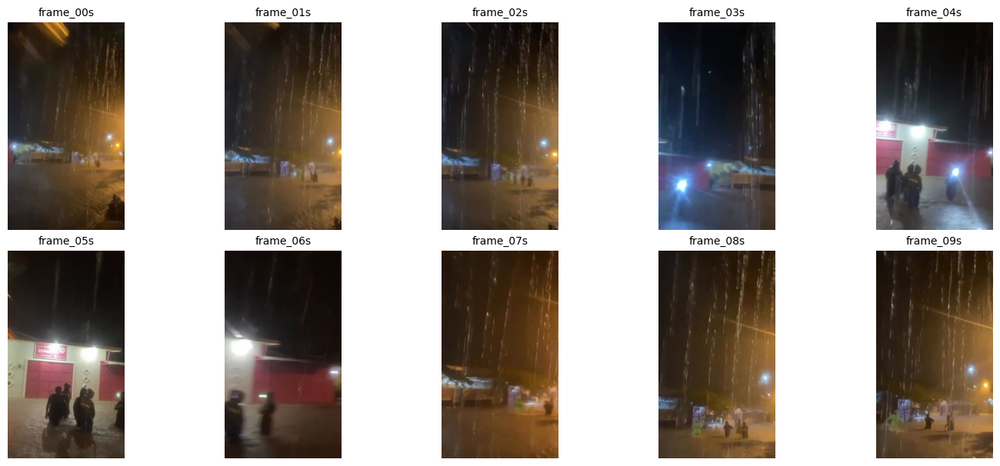

In [55]:
import cv2
import matplotlib.pyplot as plt

frames = sorted(annotation_dir.glob("*.jpg"))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, frame_path in enumerate(frames):
    image = cv2.imread(str(frame_path))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(image_rgb)
    axes[i].set_title(frame_path.stem, fontsize=10)
    axes[i].axis("off")

plt.tight_layout(pad=0.5)
plt.show()

In [56]:
# Find uploaded annotation ZIP files
zip_files = list(annotation_dir.glob("*.zip"))

print("ZIP files found:", len(zip_files))

for file in zip_files:
    print("Filename:", file.name)
    print("Size:", file.stat().st_size, "bytes")

ZIP files found: 1
Filename: labels_my-project-name_2026-11-10-07-28-01.zip
Size: 313 bytes


In [57]:
import zipfile

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    for filename in zip_ref.namelist():
        print("File:", filename)

        if filename.endswith(".txt"):
            content = zip_ref.read(filename).decode("utf-8")
            print("Contents:")
            print(content)

File: frame_05s.txt
Contents:
0 0.420696 0.744186 0.157229 0.186047
0 0.499310 0.718605 0.115853 0.190698
0 0.631713 0.752326 0.115853 0.188372
0 0.720672 0.796512 0.136541 0.244186
0 0.939985 0.762791 0.120030 0.195349


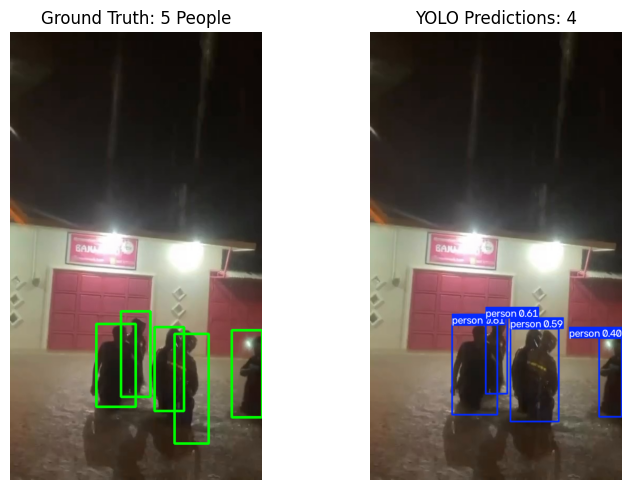

In [58]:
import cv2
import zipfile
import matplotlib.pyplot as plt

# Load original frame
image_path = annotation_dir / "frame_05s.jpg"
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(image_path)

height, width = image.shape[:2]

# Read manually annotated ground truth
with zipfile.ZipFile(zip_files[0], "r") as z:
    labels = z.read("frame_05s.txt").decode().strip().splitlines()

ground_truth = image.copy()

for line in labels:
    class_id, cx, cy, bw, bh = map(float, line.split())

    x1 = int((cx - bw / 2) * width)
    y1 = int((cy - bh / 2) * height)
    x2 = int((cx + bw / 2) * width)
    y2 = int((cy + bh / 2) * height)

    cv2.rectangle(
        ground_truth, (x1, y1), (x2, y2),
        (0, 255, 0), 3
    )

# Run YOLO on the same original image
prediction = model.predict(
    source=image,
    classes=[0],
    conf=0.25,
    device=0,
    verbose=False
)[0]

# Generate side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(8, 5))

axes[0].imshow(cv2.cvtColor(ground_truth, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Ground Truth: {len(labels)} People")

axes[1].imshow(cv2.cvtColor(prediction.plot(), cv2.COLOR_BGR2RGB))
axes[1].set_title(f"YOLO Predictions: {len(prediction.boxes)}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [59]:
import numpy as np

# Convert ground-truth YOLO coordinates to pixel coordinates
gt_boxes = []

for line in labels:
    class_id, cx, cy, bw, bh = map(float, line.split())

    gt_boxes.append([
        (cx - bw / 2) * width,
        (cy - bh / 2) * height,
        (cx + bw / 2) * width,
        (cy + bh / 2) * height
    ])

# Predicted bounding boxes
pred_boxes = prediction.boxes.xyxy.cpu().numpy().tolist()

def calculate_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, box_a[2] - box_a[0]) * max(0, box_a[3] - box_a[1])
    area_b = max(0, box_b[2] - box_b[0]) * max(0, box_b[3] - box_b[1])

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0

# Generate all possible matches
candidates = []

for gt_idx, gt_box in enumerate(gt_boxes):
    for pred_idx, pred_box in enumerate(pred_boxes):
        iou = calculate_iou(gt_box, pred_box)

        if iou >= 0.5:
            candidates.append((iou, gt_idx, pred_idx))

# Match highest IoU pairs first
matched_gt = set()
matched_pred = set()

for iou, gt_idx, pred_idx in sorted(candidates, reverse=True):
    if gt_idx not in matched_gt and pred_idx not in matched_pred:
        matched_gt.add(gt_idx)
        matched_pred.add(pred_idx)

tp = len(matched_gt)
fp = len(pred_boxes) - tp
fn = len(gt_boxes) - tp

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0

print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")

True Positives: 4
False Positives: 0
False Negatives: 1
Precision: 100.00%
Recall: 80.00%


In [60]:
# Calculate F1 score
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0
    else 0
)

print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1 Score: {f1:.2%}")

Precision: 100.00%
Recall: 80.00%
F1 Score: 88.89%


In [61]:
import json
from datetime import datetime, timezone

evaluation = {
    "experiment_id": "EXP-003",
    "project": "AI-NETRA",
    "model": "YOLO11n",
    "video": "2023020103.mp4",
    "frame": "frame_05s.jpg",
    "confidence_threshold": 0.25,
    "iou_matching_threshold": 0.50,
    "ground_truth_count": len(gt_boxes),
    "true_positives": tp,
    "false_positives": fp,
    "false_negatives": fn,
    "precision": round(precision, 4),
    "recall": round(recall, 4),
    "f1_score": round(f1, 4),
    "evaluation_scope": "Single manually annotated frame",
    "timestamp": datetime.now(timezone.utc).isoformat()
}

evaluation_path = PROJECT_ROOT / "experiments" / "EXP-003.json"

with open(evaluation_path, "w", encoding="utf-8") as file:
    json.dump(evaluation, file, indent=4)

print("Evaluation saved:", evaluation_path)

Evaluation saved: /content/drive/MyDrive/Hacks/AI-NETRA/experiments/EXP-003.json


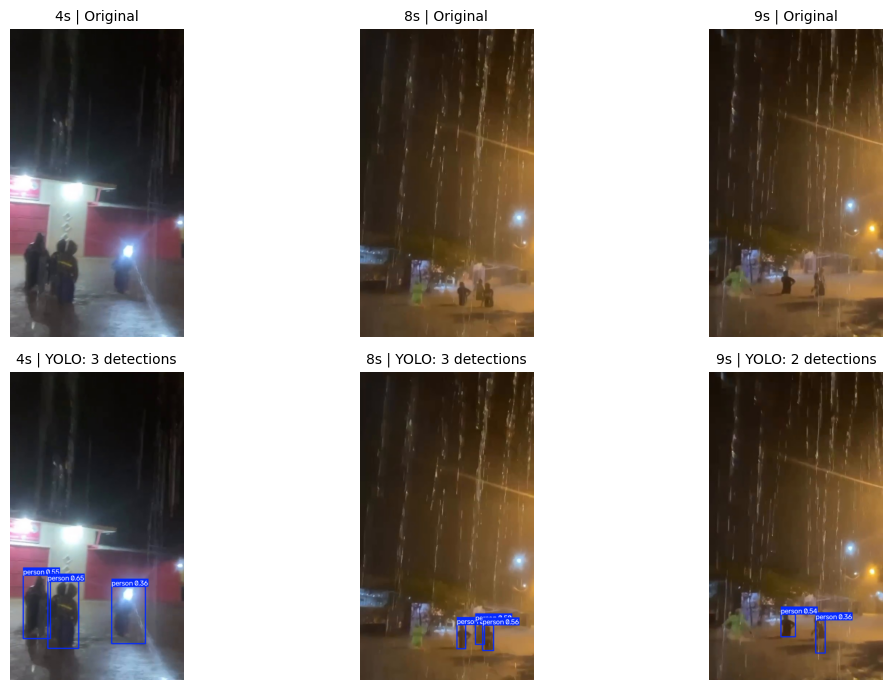

In [62]:
import cv2
import matplotlib.pyplot as plt

timestamps = [4, 8, 9]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for col, t in enumerate(timestamps):
    path = annotation_dir / f"frame_{t:02d}s.jpg"
    frame = cv2.imread(str(path))

    result = model.predict(
        frame,
        classes=[0],
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    original = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

    axes[0, col].imshow(original)
    axes[0, col].set_title(f"{t}s | Original", fontsize=10)

    axes[1, col].imshow(annotated)
    axes[1, col].set_title(
        f"{t}s | YOLO: {len(result.boxes)} detections",
        fontsize=10
    )

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [63]:
import zipfile

zip_files = sorted(annotation_dir.glob("*.zip"))

for zip_path in zip_files:
    with zipfile.ZipFile(zip_path, "r") as z:
        print(f"\nZIP: {zip_path.name}")

        for filename in z.namelist():
            if filename.endswith(".txt"):
                content = z.read(filename).decode("utf-8")
                count = len(content.strip().splitlines())

                print(f"  Annotation: {filename}")
                print(f"  Person count: {count}")


ZIP: labels_my-project-name_2026-11-10-07-28-01.zip
  Annotation: frame_05s.txt
  Person count: 5

ZIP: labels_my-project-name_2026-11-10-07-46-02.zip
  Annotation: frame_04s.txt
  Person count: 4


In [64]:
import cv2
import zipfile

# Load frame 04s
image = cv2.imread(str(annotation_dir / "frame_04s.jpg"))
height, width = image.shape[:2]

# Read the ground-truth annotations
with zipfile.ZipFile(zip_files[1], "r") as z:
    labels_04 = z.read("frame_04s.txt").decode().strip().splitlines()

gt_boxes_04 = []

for line in labels_04:
    class_id, cx, cy, bw, bh = map(float, line.split())

    gt_boxes_04.append([
        (cx - bw / 2) * width,
        (cy - bh / 2) * height,
        (cx + bw / 2) * width,
        (cy + bh / 2) * height
    ])

# Run YOLO inference
prediction_04 = model.predict(
    image,
    classes=[0],
    conf=0.25,
    device=0,
    verbose=False
)[0]

pred_boxes_04 = prediction_04.boxes.xyxy.cpu().numpy().tolist()

# Match predictions against ground truth
candidates = []

for gt_idx, gt_box in enumerate(gt_boxes_04):
    for pred_idx, pred_box in enumerate(pred_boxes_04):
        iou = calculate_iou(gt_box, pred_box)

        if iou >= 0.5:
            candidates.append((iou, gt_idx, pred_idx))

matched_gt = set()
matched_pred = set()

for iou, gt_idx, pred_idx in sorted(candidates, reverse=True):
    if gt_idx not in matched_gt and pred_idx not in matched_pred:
        matched_gt.add(gt_idx)
        matched_pred.add(pred_idx)

tp_04 = len(matched_gt)
fp_04 = len(pred_boxes_04) - tp_04
fn_04 = len(gt_boxes_04) - tp_04

precision_04 = tp_04 / (tp_04 + fp_04) if tp_04 + fp_04 else 0
recall_04 = tp_04 / (tp_04 + fn_04) if tp_04 + fn_04 else 0

f1_04 = (
    2 * precision_04 * recall_04 / (precision_04 + recall_04)
    if precision_04 + recall_04 else 0
)

print("Ground Truth:", len(gt_boxes_04))
print("YOLO Detections:", len(pred_boxes_04))
print("True Positives:", tp_04)
print("False Positives:", fp_04)
print("False Negatives:", fn_04)
print(f"Precision: {precision_04:.2%}")
print(f"Recall: {recall_04:.2%}")
print(f"F1 Score: {f1_04:.2%}")

Ground Truth: 4
YOLO Detections: 3
True Positives: 2
False Positives: 1
False Negatives: 2
Precision: 66.67%
Recall: 50.00%
F1 Score: 57.14%


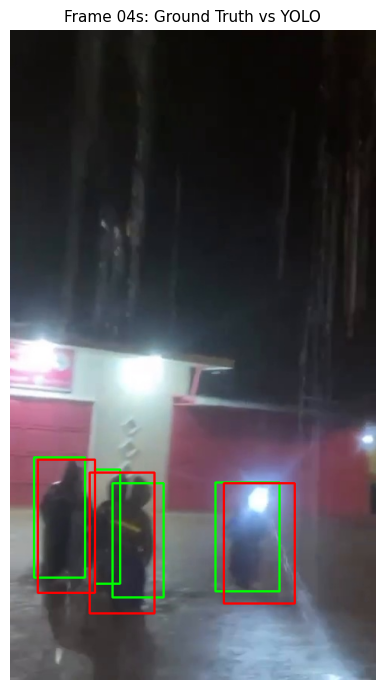

In [65]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread(str(annotation_dir / "frame_04s.jpg"))

comparison = image.copy()

# Green = manually annotated ground truth
for box in gt_boxes_04:
    x1, y1, x2, y2 = map(int, box)

    cv2.rectangle(
        comparison,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

# Red = YOLO predictions
for box in pred_boxes_04:
    x1, y1, x2, y2 = map(int, box)

    cv2.rectangle(
        comparison,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

plt.figure(figsize=(5, 7))

plt.imshow(cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB))

plt.title("Frame 04s: Ground Truth vs YOLO", fontsize=11)

plt.axis("off")
plt.tight_layout()
plt.show()

In [66]:
import numpy as np
import pandas as pd

iou_matrix = np.array([
    [calculate_iou(gt, pred) for pred in pred_boxes_04]
    for gt in gt_boxes_04
])

df = pd.DataFrame(
    iou_matrix,
    index=[f"Person {i+1}" for i in range(len(gt_boxes_04))],
    columns=[f"Prediction {i+1}" for i in range(len(pred_boxes_04))]
)

print("IoU Matrix:")
print(df.round(3).to_string())

print("\nMatching threshold: 0.50")

IoU Matrix:
          Prediction 1  Prediction 2  Prediction 3
Person 1         0.000         0.680         0.000
Person 2         0.311         0.003         0.000
Person 3         0.478         0.000         0.000
Person 4         0.000         0.000         0.628

Matching threshold: 0.50


In [67]:
from ultralytics import YOLO

# Load YOLO11 Small
model_small = YOLO("yolo11s.pt")

print("YOLO11s loaded successfully!")
print("Model parameters:", sum(p.numel() for p in model_small.model.parameters()))

YOLO11s loaded successfully!
Model parameters: 9458752


In [68]:
# Compare both models under identical conditions
models = {
    "YOLO11n": model,
    "YOLO11s": model_small
}

for name, detector in models.items():

    result = detector.predict(
        source=image,
        classes=[0],
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    pred_boxes = result.boxes.xyxy.cpu().numpy().tolist()

    candidates = []

    for gt_idx, gt_box in enumerate(gt_boxes_04):
        for pred_idx, pred_box in enumerate(pred_boxes):
            iou = calculate_iou(gt_box, pred_box)

            if iou >= 0.5:
                candidates.append((iou, gt_idx, pred_idx))

    matched_gt = set()
    matched_pred = set()

    for iou, gt_idx, pred_idx in sorted(candidates, reverse=True):
        if gt_idx not in matched_gt and pred_idx not in matched_pred:
            matched_gt.add(gt_idx)
            matched_pred.add(pred_idx)

    tp = len(matched_gt)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes_04) - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(f"\n{name}")
    print(f"Detections: {len(pred_boxes)}")
    print(f"TP: {tp}, FP: {fp}, FN: {fn}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
    print(f"F1 Score: {f1:.2%}")


YOLO11n
Detections: 3
TP: 2, FP: 1, FN: 2
Precision: 66.67%
Recall: 50.00%
F1 Score: 57.14%

YOLO11s
Detections: 2
TP: 2, FP: 0, FN: 2
Precision: 100.00%
Recall: 50.00%
F1 Score: 66.67%


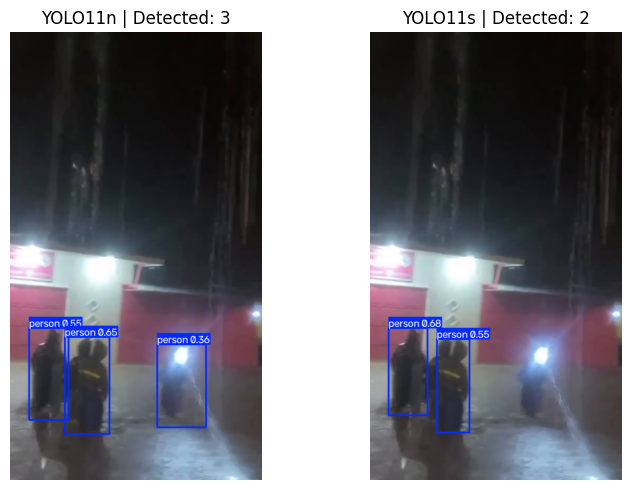

In [69]:
import cv2
import matplotlib.pyplot as plt

frame = cv2.imread(str(annotation_dir / "frame_04s.jpg"))

fig, axes = plt.subplots(1, 2, figsize=(8, 5))

for ax, (name, detector) in zip(
    axes,
    [("YOLO11n", model), ("YOLO11s", model_small)]
):
    result = detector.predict(
        frame,
        classes=[0],
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    annotated = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(annotated)
    ax.set_title(f"{name} | Detected: {len(result.boxes)}")
    ax.axis("off")

plt.tight_layout()
plt.show()

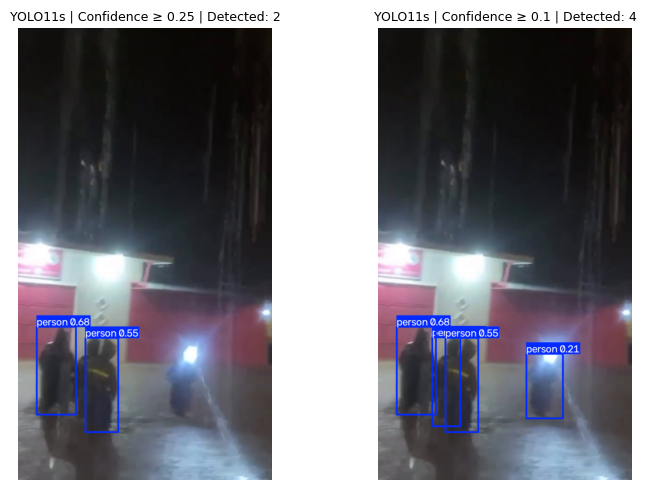

In [70]:
import cv2
import matplotlib.pyplot as plt

frame = cv2.imread(str(annotation_dir / "frame_04s.jpg"))

fig, axes = plt.subplots(1, 2, figsize=(8, 5))

for ax, threshold in zip(axes, [0.25, 0.10]):

    result = model_small.predict(
        source=frame,
        classes=[0],
        conf=threshold,
        device=0,
        verbose=False
    )[0]

    annotated = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(annotated)
    ax.set_title(
        f"YOLO11s | Confidence ≥ {threshold} | Detected: {len(result.boxes)}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [71]:
# Run YOLO11s with lower confidence
result = model_small.predict(
    source=frame,
    classes=[0],
    conf=0.10,
    device=0,
    verbose=False
)[0]

pred_boxes = result.boxes.xyxy.cpu().numpy().tolist()

# Generate possible matches using IoU >= 0.50
candidates = []

for gt_idx, gt_box in enumerate(gt_boxes_04):
    for pred_idx, pred_box in enumerate(pred_boxes):
        iou = calculate_iou(gt_box, pred_box)

        if iou >= 0.50:
            candidates.append((iou, gt_idx, pred_idx))

matched_gt = set()
matched_pred = set()

for iou, gt_idx, pred_idx in sorted(candidates, reverse=True):
    if gt_idx not in matched_gt and pred_idx not in matched_pred:
        matched_gt.add(gt_idx)
        matched_pred.add(pred_idx)

tp = len(matched_gt)
fp = len(pred_boxes) - tp
fn = len(gt_boxes_04) - tp

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("Ground Truth:", len(gt_boxes_04))
print("YOLO Detections:", len(pred_boxes))
print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1 Score: {f1:.2%}")

Ground Truth: 4
YOLO Detections: 4
True Positives: 4
False Positives: 0
False Negatives: 0
Precision: 100.00%
Recall: 100.00%
F1 Score: 100.00%


In [72]:
import cv2
import zipfile

# Load frame 05s
frame_05 = cv2.imread(str(annotation_dir / "frame_05s.jpg"))

# Read the manually annotated ground truth
with zipfile.ZipFile(zip_files[0], "r") as z:
    labels_05 = z.read("frame_05s.txt").decode().strip().splitlines()

h, w = frame_05.shape[:2]

gt_boxes_05 = []

for line in labels_05:
    class_id, cx, cy, bw, bh = map(float, line.split())

    gt_boxes_05.append([
        (cx - bw / 2) * w,
        (cy - bh / 2) * h,
        (cx + bw / 2) * w,
        (cy + bh / 2) * h
    ])

# Run YOLO11s inference
result_05 = model_small.predict(
    source=frame_05,
    classes=[0],
    conf=0.10,
    device=0,
    verbose=False
)[0]

pred_boxes_05 = result_05.boxes.xyxy.cpu().numpy().tolist()

# Match predictions to ground truth
candidates = []

for gt_idx, gt_box in enumerate(gt_boxes_05):
    for pred_idx, pred_box in enumerate(pred_boxes_05):
        iou = calculate_iou(gt_box, pred_box)

        if iou >= 0.50:
            candidates.append((iou, gt_idx, pred_idx))

matched_gt = set()
matched_pred = set()

for iou, gt_idx, pred_idx in sorted(candidates, reverse=True):
    if gt_idx not in matched_gt and pred_idx not in matched_pred:
        matched_gt.add(gt_idx)
        matched_pred.add(pred_idx)

tp_05 = len(matched_gt)
fp_05 = len(pred_boxes_05) - tp_05
fn_05 = len(gt_boxes_05) - tp_05

precision_05 = tp_05 / (tp_05 + fp_05) if tp_05 + fp_05 else 0
recall_05 = tp_05 / (tp_05 + fn_05) if tp_05 + fn_05 else 0

f1_05 = (
    2 * precision_05 * recall_05 / (precision_05 + recall_05)
    if precision_05 + recall_05 else 0
)

print("Ground Truth:", len(gt_boxes_05))
print("YOLO Detections:", len(pred_boxes_05))
print("True Positives:", tp_05)
print("False Positives:", fp_05)
print("False Negatives:", fn_05)
print(f"Precision: {precision_05:.2%}")
print(f"Recall: {recall_05:.2%}")
print(f"F1 Score: {f1_05:.2%}")

Ground Truth: 5
YOLO Detections: 6
True Positives: 4
False Positives: 2
False Negatives: 1
Precision: 66.67%
Recall: 80.00%
F1 Score: 72.73%


In [73]:
# YOLO11s, confidence threshold = 0.10
# Frame 04s: TP=4, FP=0, FN=0
# Frame 05s: TP=4, FP=2, FN=1

total_tp = 4 + tp_05
total_fp = 0 + fp_05
total_fn = 0 + fn_05

combined_precision = total_tp / (total_tp + total_fp)
combined_recall = total_tp / (total_tp + total_fn)

combined_f1 = (
    2 * combined_precision * combined_recall
    / (combined_precision + combined_recall)
)

print("Total Ground Truth:", total_tp + total_fn)
print("True Positives:", total_tp)
print("False Positives:", total_fp)
print("False Negatives:", total_fn)
print(f"Combined Precision: {combined_precision:.2%}")
print(f"Combined Recall: {combined_recall:.2%}")
print(f"Combined F1 Score: {combined_f1:.2%}")

Total Ground Truth: 9
True Positives: 8
False Positives: 2
False Negatives: 1
Combined Precision: 80.00%
Combined Recall: 88.89%
Combined F1 Score: 84.21%


In [74]:
import json
from datetime import datetime, timezone

evaluation = {
    "experiment_id": "EXP-004",
    "project": "AI-NETRA",
    "model": "YOLO11s",
    "confidence_threshold": 0.10,
    "iou_threshold": 0.50,
    "video": "2023020103.mp4",
    "evaluated_frames": ["frame_04s.jpg", "frame_05s.jpg"],
    "ground_truth_count": 9,
    "true_positives": total_tp,
    "false_positives": total_fp,
    "false_negatives": total_fn,
    "precision": round(combined_precision, 4),
    "recall": round(combined_recall, 4),
    "f1_score": round(combined_f1, 4),
    "evaluation_scope": "Two manually annotated frames",
    "timestamp": datetime.now(timezone.utc).isoformat()
}

evaluation_path = PROJECT_ROOT / "experiments" / "EXP-004.json"

with open(evaluation_path, "w", encoding="utf-8") as f:
    json.dump(evaluation, f, indent=4)

print("Evaluation saved:", evaluation_path)

Evaluation saved: /content/drive/MyDrive/Hacks/AI-NETRA/experiments/EXP-004.json


In [75]:
import shutil
from pathlib import Path

source = Path("yolo11s.pt")
destination = PROJECT_ROOT / "models" / "yolo11s.pt"

shutil.copy2(source, destination)

print("Model saved:", destination)
print("Size (MB):", round(destination.stat().st_size / (1024 * 1024), 2))

Model saved: /content/drive/MyDrive/Hacks/AI-NETRA/models/yolo11s.pt
Size (MB): 18.42


In [76]:
import cv2

day_video = flood_video_dir / "2023020108.mp4"

cap = cv2.VideoCapture(str(day_video))
fps = cap.get(cv2.CAP_PROP_FPS)

models = {
    "YOLO11n": model,
    "YOLO11s": model_small
}

# Analyze frames at 2, 4, 6, 8, and 10 seconds
timestamps = [2, 4, 6, 8, 10]

print(f"{'Time':<10} {'YOLO11n':<12} {'YOLO11s':<12}")
print("-" * 34)

for timestamp in timestamps:
    cap.set(cv2.CAP_PROP_POS_MSEC, timestamp * 1000)
    success, frame = cap.read()

    if not success:
        continue

    counts = {}

    for name, detector in models.items():
        result = detector.predict(
            source=frame,
            classes=[0],
            conf=0.10,
            device=0,
            verbose=False
        )[0]

        counts[name] = len(result.boxes)

    print(
        f"{timestamp}s{'':<8}"
        f"{counts['YOLO11n']:<12}"
        f"{counts['YOLO11s']:<12}"
    )

cap.release()

Time       YOLO11n      YOLO11s     
----------------------------------
2s        3           0           
4s        0           0           
6s        0           0           
8s        2           0           
10s        2           0           


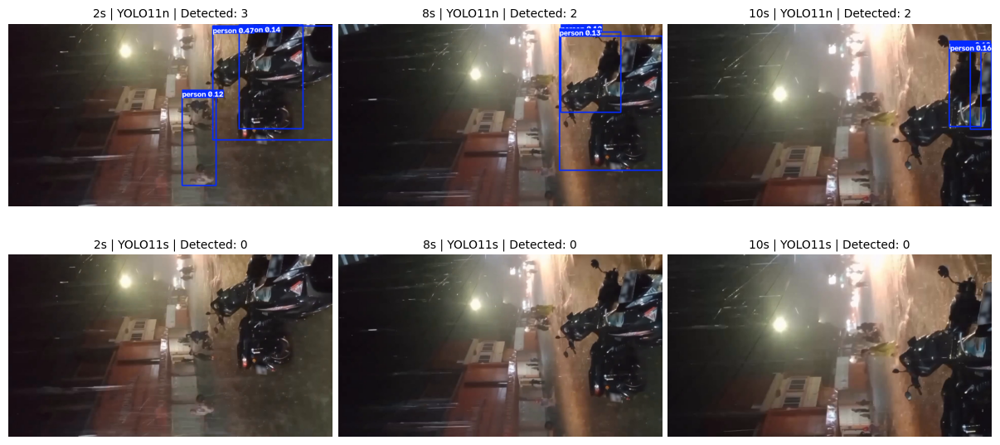

In [77]:
import cv2
import matplotlib.pyplot as plt

timestamps = [2, 8, 10]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))

cap = cv2.VideoCapture(str(day_video))

for col, timestamp in enumerate(timestamps):
    cap.set(cv2.CAP_PROP_POS_MSEC, timestamp * 1000)
    success, frame = cap.read()

    if not success:
        continue

    for row, (name, detector) in enumerate([
        ("YOLO11n", model),
        ("YOLO11s", model_small)
    ]):
        result = detector.predict(
            source=frame,
            classes=[0],
            conf=0.10,
            device=0,
            verbose=False
        )[0]

        annotated = cv2.cvtColor(
            result.plot(),
            cv2.COLOR_BGR2RGB
        )

        axes[row, col].imshow(annotated)
        axes[row, col].set_title(
            f"{timestamp}s | {name} | Detected: {len(result.boxes)}",
            fontsize=10
        )
        axes[row, col].axis("off")

cap.release()

plt.tight_layout(pad=0.5)
plt.show()

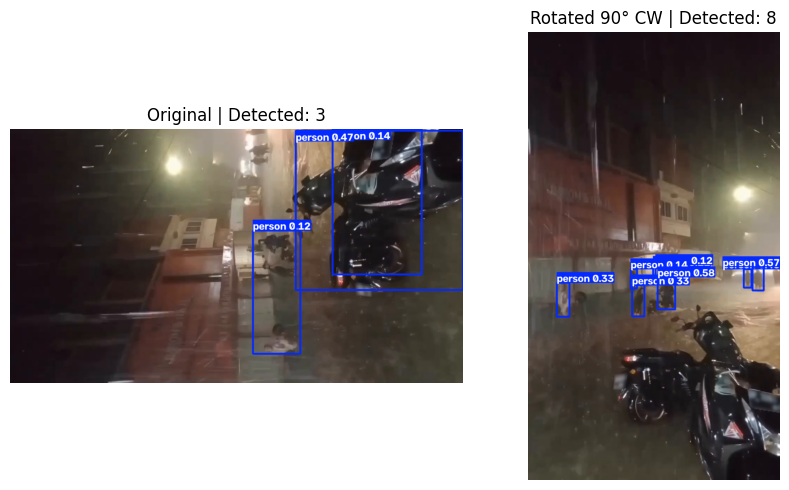

In [78]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(str(day_video))
cap.set(cv2.CAP_PROP_POS_MSEC, 2000)

success, frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("Unable to read video frame")

# Rotate frame 90 degrees clockwise
rotated = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)

fig, axes = plt.subplots(1, 2, figsize=(9, 5))

for ax, (label, image) in zip(
    axes,
    [("Original", frame), ("Rotated 90° CW", rotated)]
):
    result = model.predict(
        source=image,
        classes=[0],
        conf=0.10,
        device=0,
        verbose=False
    )[0]

    annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

    ax.imshow(annotated)
    ax.set_title(f"{label} | Detected: {len(result.boxes)}")
    ax.axis("off")

plt.tight_layout()
plt.show()

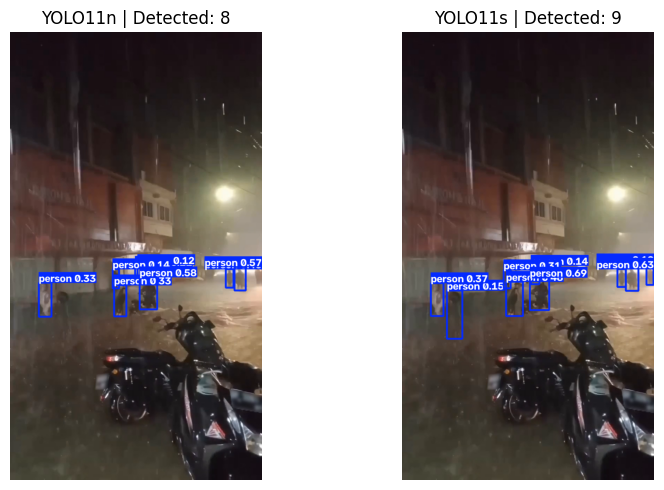

In [79]:
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 5))

for ax, (name, detector) in zip(
    axes,
    [("YOLO11n", model), ("YOLO11s", model_small)]
):
    result = detector.predict(
        source=rotated,
        classes=[0],
        conf=0.10,
        device=0,
        verbose=False
    )[0]

    annotated = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(annotated)
    ax.set_title(f"{name} | Detected: {len(result.boxes)}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [80]:
from pathlib import Path
import cv2

day_annotation_dir = PROJECT_ROOT / "datasets" / "annotations" / "EXP-005"
day_annotation_dir.mkdir(parents=True, exist_ok=True)

frame_path = day_annotation_dir / "frame_02s_rotated.jpg"

cv2.imwrite(str(frame_path), rotated)

print("Frame saved:", frame_path)
print("Resolution:", rotated.shape[1], "x", rotated.shape[0])

Frame saved: /content/drive/MyDrive/Hacks/AI-NETRA/datasets/annotations/EXP-005/frame_02s_rotated.jpg
Resolution: 720 x 1280


In [82]:
import zipfile

exp005_dir = PROJECT_ROOT / "datasets" / "annotations" / "EXP-005"

zip_files_005 = list(exp005_dir.glob("*.zip"))

print("ZIP files found:", len(zip_files_005))

for zip_path in zip_files_005:
    with zipfile.ZipFile(zip_path, "r") as z:
        for filename in z.namelist():
            if filename.endswith(".txt"):
                labels_005 = z.read(filename).decode().strip().splitlines()

                print("Annotation file:", filename)
                print("Total people annotated:", len(labels_005))

ZIP files found: 1
Annotation file: frame_02s_rotated.txt
Total people annotated: 9


In [83]:
import cv2
import zipfile

# Load annotated image
image = cv2.imread(str(exp005_dir / "frame_02s_rotated.jpg"))
h, w = image.shape[:2]

# Read ground-truth labels
with zipfile.ZipFile(zip_files_005[0], "r") as z:
    labels = z.read("frame_02s_rotated.txt").decode().strip().splitlines()

gt_boxes = []

for line in labels:
    class_id, cx, cy, bw, bh = map(float, line.split())

    gt_boxes.append([
        (cx - bw / 2) * w,
        (cy - bh / 2) * h,
        (cx + bw / 2) * w,
        (cy + bh / 2) * h
    ])

# Compare both models
for name, detector in [
    ("YOLO11n", model),
    ("YOLO11s", model_small)
]:
    result = detector.predict(
        source=image,
        classes=[0],
        conf=0.10,
        device=0,
        verbose=False
    )[0]

    pred_boxes = result.boxes.xyxy.cpu().numpy().tolist()

    candidates = []

    for gt_idx, gt_box in enumerate(gt_boxes):
        for pred_idx, pred_box in enumerate(pred_boxes):
            iou = calculate_iou(gt_box, pred_box)

            if iou >= 0.50:
                candidates.append((iou, gt_idx, pred_idx))

    matched_gt = set()
    matched_pred = set()

    for iou, gt_idx, pred_idx in sorted(candidates, reverse=True):
        if gt_idx not in matched_gt and pred_idx not in matched_pred:
            matched_gt.add(gt_idx)
            matched_pred.add(pred_idx)

    tp = len(matched_gt)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    print(f"\n{name}")
    print(f"Ground Truth: {len(gt_boxes)}")
    print(f"Detections: {len(pred_boxes)}")
    print(f"TP: {tp}, FP: {fp}, FN: {fn}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
    print(f"F1 Score: {f1:.2%}")


YOLO11n
Ground Truth: 9
Detections: 7
TP: 3, FP: 4, FN: 6
Precision: 42.86%
Recall: 33.33%
F1 Score: 37.50%

YOLO11s
Ground Truth: 9
Detections: 9
TP: 4, FP: 5, FN: 5
Precision: 44.44%
Recall: 44.44%
F1 Score: 44.44%


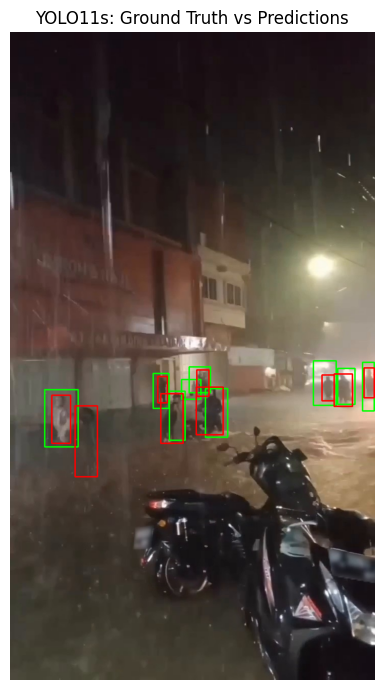

In [84]:
import cv2
import matplotlib.pyplot as plt

# Load the correctly oriented frame
frame = cv2.imread(str(exp005_dir / "frame_02s_rotated.jpg"))

# Run YOLO11s
result = model_small.predict(
    source=frame,
    classes=[0],
    conf=0.10,
    device=0,
    verbose=False
)[0]

comparison = frame.copy()

# Green = Ground-truth annotations
for box in gt_boxes:
    x1, y1, x2, y2 = map(int, box)
    cv2.rectangle(
        comparison,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

# Red = YOLO11s predictions
for box in result.boxes.xyxy.cpu().numpy():
    x1, y1, x2, y2 = map(int, box)
    cv2.rectangle(
        comparison,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

# Compact display
plt.figure(figsize=(4, 7))
plt.imshow(cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB))
plt.title("YOLO11s: Ground Truth vs Predictions")
plt.axis("off")
plt.tight_layout()
plt.show()

In [85]:
pred_boxes = result.boxes.xyxy.cpu().numpy().tolist()

for threshold in [0.30, 0.40, 0.50]:
    candidates = []

    for gt_idx, gt_box in enumerate(gt_boxes):
        for pred_idx, pred_box in enumerate(pred_boxes):
            iou = calculate_iou(gt_box, pred_box)

            if iou >= threshold:
                candidates.append((iou, gt_idx, pred_idx))

    matched_gt = set()
    matched_pred = set()

    for iou, gt_idx, pred_idx in sorted(candidates, reverse=True):
        if gt_idx not in matched_gt and pred_idx not in matched_pred:
            matched_gt.add(gt_idx)
            matched_pred.add(pred_idx)

    tp = len(matched_gt)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    print(
        f"IoU ≥ {threshold:.2f} | "
        f"TP: {tp} | FP: {fp} | FN: {fn} | "
        f"Precision: {precision:.2%} | Recall: {recall:.2%}"
    )

IoU ≥ 0.30 | TP: 7 | FP: 2 | FN: 2 | Precision: 77.78% | Recall: 77.78%
IoU ≥ 0.40 | TP: 7 | FP: 2 | FN: 2 | Precision: 77.78% | Recall: 77.78%
IoU ≥ 0.50 | TP: 4 | FP: 5 | FN: 5 | Precision: 44.44% | Recall: 44.44%


In [86]:
for gt_idx, gt_box in enumerate(gt_boxes):
    overlaps = [
        calculate_iou(gt_box, pred_box)
        for pred_box in pred_boxes
    ]

    best_iou = max(overlaps, default=0)

    if 0.40 <= best_iou < 0.50:
        print(
            f"Person {gt_idx + 1}: "
            f"Best IoU = {best_iou:.3f} "
            f"(Borderline localization)"
        )

Person 1: Best IoU = 0.458 (Borderline localization)
Person 4: Best IoU = 0.472 (Borderline localization)
Person 5: Best IoU = 0.452 (Borderline localization)


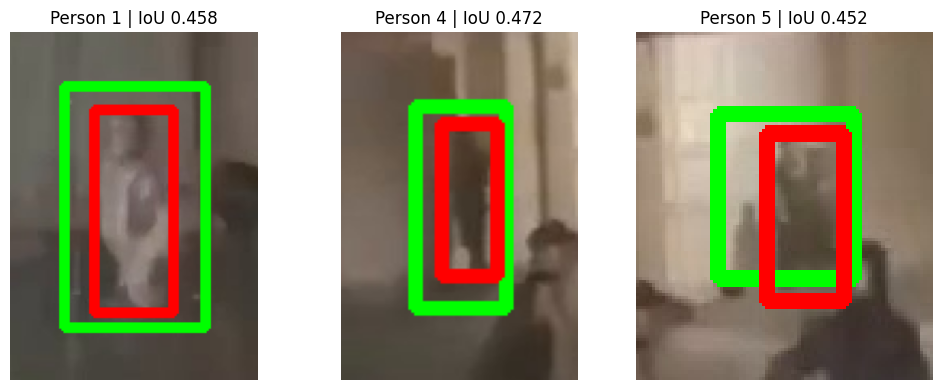

In [87]:
import cv2
import matplotlib.pyplot as plt

frame = cv2.imread(str(exp005_dir / "frame_02s_rotated.jpg"))

borderline = []

for gt_idx, gt_box in enumerate(gt_boxes):
    overlaps = [
        calculate_iou(gt_box, pred_box)
        for pred_box in pred_boxes
    ]

    if not overlaps:
        continue

    best_idx = max(range(len(overlaps)), key=lambda i: overlaps[i])
    best_iou = overlaps[best_idx]

    if 0.40 <= best_iou < 0.50:
        borderline.append((gt_idx, best_idx, best_iou))

fig, axes = plt.subplots(1, len(borderline), figsize=(10, 4))

if len(borderline) == 1:
    axes = [axes]

for ax, (gt_idx, pred_idx, iou) in zip(axes, borderline):

    comparison = frame.copy()

    # Ground truth - Green
    x1, y1, x2, y2 = map(int, gt_boxes[gt_idx])
    cv2.rectangle(comparison, (x1, y1), (x2, y2), (0, 255, 0), 3)

    # Prediction - Red
    x1, y1, x2, y2 = map(int, pred_boxes[pred_idx])
    cv2.rectangle(comparison, (x1, y1), (x2, y2), (0, 0, 255), 3)

    # Crop around both bounding boxes
    boxes = [gt_boxes[gt_idx], pred_boxes[pred_idx]]

    crop_x1 = max(0, int(min(b[0] for b in boxes) - 25))
    crop_y1 = max(0, int(min(b[1] for b in boxes) - 25))
    crop_x2 = min(frame.shape[1], int(max(b[2] for b in boxes) + 25))
    crop_y2 = min(frame.shape[0], int(max(b[3] for b in boxes) + 25))

    crop = comparison[crop_y1:crop_y2, crop_x1:crop_x2]

    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Person {gt_idx + 1} | IoU {iou:.3f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

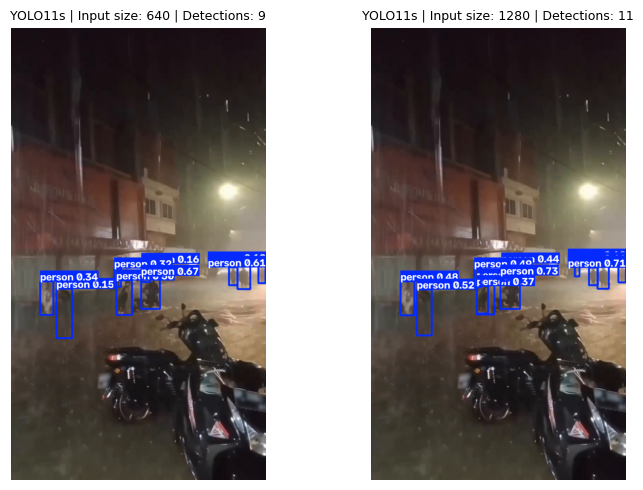

In [88]:
import cv2
import matplotlib.pyplot as plt

frame = cv2.imread(str(exp005_dir / "frame_02s_rotated.jpg"))

fig, axes = plt.subplots(1, 2, figsize=(8, 5))

for ax, imgsz in zip(axes, [640, 1280]):

    result = model_small.predict(
        source=frame,
        classes=[0],
        conf=0.10,
        imgsz=imgsz,
        device=0,
        verbose=False
    )[0]

    annotated = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(annotated)
    ax.set_title(
        f"YOLO11s | Input size: {imgsz} | "
        f"Detections: {len(result.boxes)}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [89]:
# Compare YOLO11s accuracy at two input resolutions

for imgsz in [640, 1280]:

    result = model_small.predict(
        source=frame,
        classes=[0],
        conf=0.10,
        imgsz=imgsz,
        device=0,
        verbose=False
    )[0]

    predictions = result.boxes.xyxy.cpu().numpy().tolist()

    candidates = []

    for gt_idx, gt_box in enumerate(gt_boxes):
        for pred_idx, pred_box in enumerate(predictions):
            iou = calculate_iou(gt_box, pred_box)

            if iou >= 0.50:
                candidates.append((iou, gt_idx, pred_idx))

    matched_gt = set()
    matched_pred = set()

    for iou, gt_idx, pred_idx in sorted(candidates, reverse=True):
        if gt_idx not in matched_gt and pred_idx not in matched_pred:
            matched_gt.add(gt_idx)
            matched_pred.add(pred_idx)

    tp = len(matched_gt)
    fp = len(predictions) - tp
    fn = len(gt_boxes) - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(f"\nInput Size: {imgsz}")
    print(f"Detections: {len(predictions)}")
    print(f"TP: {tp}, FP: {fp}, FN: {fn}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
    print(f"F1 Score: {f1:.2%}")


Input Size: 640
Detections: 9
TP: 4, FP: 5, FN: 5
Precision: 44.44%
Recall: 44.44%
F1 Score: 44.44%

Input Size: 1280
Detections: 11
TP: 3, FP: 8, FN: 6
Precision: 27.27%
Recall: 33.33%
F1 Score: 30.00%


In [90]:
import cv2

frame = cv2.imread(str(exp005_dir / "frame_02s_rotated.jpg"))

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Enhance luminance while preserving color
lab = cv2.cvtColor(frame, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)

enhanced = cv2.cvtColor(
    cv2.merge((clahe.apply(l), a, b)),
    cv2.COLOR_LAB2BGR
)

for name, image_input in [
    ("Original", frame),
    ("CLAHE", enhanced)
]:
    result = model_small.predict(
        source=image_input,
        classes=[0],
        conf=0.10,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    predictions = result.boxes.xyxy.cpu().numpy().tolist()
    candidates = []

    for gt_idx, gt_box in enumerate(gt_boxes):
        for pred_idx, pred_box in enumerate(predictions):
            iou = calculate_iou(gt_box, pred_box)
            if iou >= 0.50:
                candidates.append((iou, gt_idx, pred_idx))

    matched_gt, matched_pred = set(), set()

    for iou, gt_idx, pred_idx in sorted(candidates, reverse=True):
        if gt_idx not in matched_gt and pred_idx not in matched_pred:
            matched_gt.add(gt_idx)
            matched_pred.add(pred_idx)

    tp = len(matched_gt)
    fp = len(predictions) - tp
    fn = len(gt_boxes) - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    print(f"\n{name}")
    print(f"Detections: {len(predictions)}")
    print(f"TP: {tp}, FP: {fp}, FN: {fn}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
    print(f"F1 Score: {f1:.2%}")


Original
Detections: 9
TP: 4, FP: 5, FN: 5
Precision: 44.44%
Recall: 44.44%
F1 Score: 44.44%

CLAHE
Detections: 10
TP: 4, FP: 6, FN: 5
Precision: 40.00%
Recall: 44.44%
F1 Score: 42.11%


In [91]:
import json
from datetime import datetime, timezone

experiment = {
    "experiment_id": "EXP-005",
    "project": "AI-NETRA",
    "video": "2023020108.mp4",
    "frame": "frame_02s_rotated.jpg",
    "ground_truth_count": 9,
    "confidence_threshold": 0.10,
    "iou_threshold": 0.50,
    "results": {
        "YOLO11n_640": {
            "tp": 3, "fp": 4, "fn": 6,
            "precision": 0.4286,
            "recall": 0.3333,
            "f1": 0.375
        },
        "YOLO11s_640": {
            "tp": 4, "fp": 5, "fn": 5,
            "precision": 0.4444,
            "recall": 0.4444,
            "f1": 0.4444
        },
        "YOLO11s_1280": {
            "tp": 3, "fp": 8, "fn": 6,
            "precision": 0.2727,
            "recall": 0.3333,
            "f1": 0.30
        },
        "YOLO11s_640_CLAHE": {
            "tp": 4, "fp": 6, "fn": 5,
            "precision": 0.40,
            "recall": 0.4444,
            "f1": 0.4211
        }
    },
    "evaluation_scope": "Single manually annotated frame",
    "timestamp": datetime.now(timezone.utc).isoformat()
}

experiment_path = PROJECT_ROOT / "experiments" / "EXP-005.json"

with open(experiment_path, "w", encoding="utf-8") as f:
    json.dump(experiment, f, indent=4)

print("Experiment saved:", experiment_path)

Experiment saved: /content/drive/MyDrive/Hacks/AI-NETRA/experiments/EXP-005.json


In [92]:
from pathlib import Path

evaluation_dir = PROJECT_ROOT / "datasets" / "evaluation"

evaluation_dir.mkdir(parents=True, exist_ok=True)

print("Evaluation directory:", evaluation_dir)
print("Directory exists:", evaluation_dir.exists())

Evaluation directory: /content/drive/MyDrive/Hacks/AI-NETRA/datasets/evaluation
Directory exists: True


In [93]:
import cv2

total_saved = 0

for video in videos:
    cap = cv2.VideoCapture(str(video))

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if not cap.isOpened() or total_frames <= 0:
        print(f"Skipped: {video.name}")
        cap.release()
        continue

    # Sample frames at 10%, 30%, 50%, 70%, and 90%
    sample_positions = [0.1, 0.3, 0.5, 0.7, 0.9]

    saved = 0

    for position in sample_positions:
        frame_index = int((total_frames - 1) * position)

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
        success, frame = cap.read()

        if not success:
            continue

        output_path = (
            evaluation_dir /
            f"{video.stem}_frame_{frame_index:05d}.jpg"
        )

        if cv2.imwrite(str(output_path), frame):
            saved += 1

    cap.release()
    total_saved += saved

    print(f"{video.name}: {saved} frames saved")

print(f"\nTotal frames saved: {total_saved}")

2022111805.mp4: 5 frames saved
2023020103.mp4: 5 frames saved
2023020104.mp4: 5 frames saved
2023020108.mp4: 5 frames saved
2023033002.mp4: 5 frames saved

Total frames saved: 25


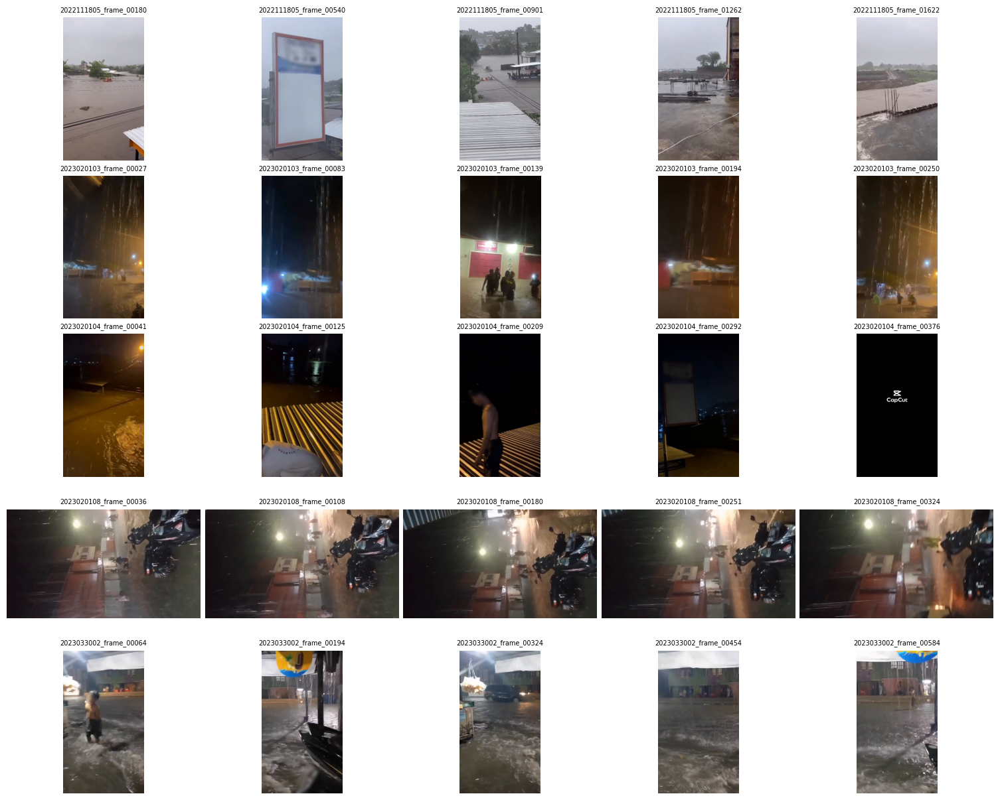

In [94]:
import cv2
import matplotlib.pyplot as plt

frame_files = sorted(evaluation_dir.glob("*.jpg"))

fig, axes = plt.subplots(5, 5, figsize=(15, 12))
axes = axes.flatten()

for i, frame_path in enumerate(frame_files[:25]):
    frame = cv2.imread(str(frame_path))

    if frame is None:
        axes[i].axis("off")
        continue

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    axes[i].imshow(frame_rgb)
    axes[i].set_title(
        frame_path.stem,
        fontsize=7
    )
    axes[i].axis("off")

for i in range(len(frame_files), 25):
    axes[i].axis("off")

plt.tight_layout(pad=0.5)
plt.show()

In [95]:
import cv2

sideways_frames = sorted(
    evaluation_dir.glob("2023020108_frame_*.jpg")
)

for frame_path in sideways_frames:
    frame = cv2.imread(str(frame_path))

    if frame is None:
        print("Skipped:", frame_path.name)
        continue

    corrected = cv2.rotate(
        frame,
        cv2.ROTATE_90_CLOCKWISE
    )

    # Save with a separate filename to preserve the original
    output_path = evaluation_dir / (
        frame_path.stem + "_upright.jpg"
    )

    cv2.imwrite(str(output_path), corrected)

    print("Corrected:", output_path.name)

print(f"\nTotal corrected: {len(sideways_frames)}")

Corrected: 2023020108_frame_00036_upright.jpg
Corrected: 2023020108_frame_00108_upright.jpg
Corrected: 2023020108_frame_00180_upright.jpg
Corrected: 2023020108_frame_00251_upright.jpg
Corrected: 2023020108_frame_00324_upright.jpg

Total corrected: 5


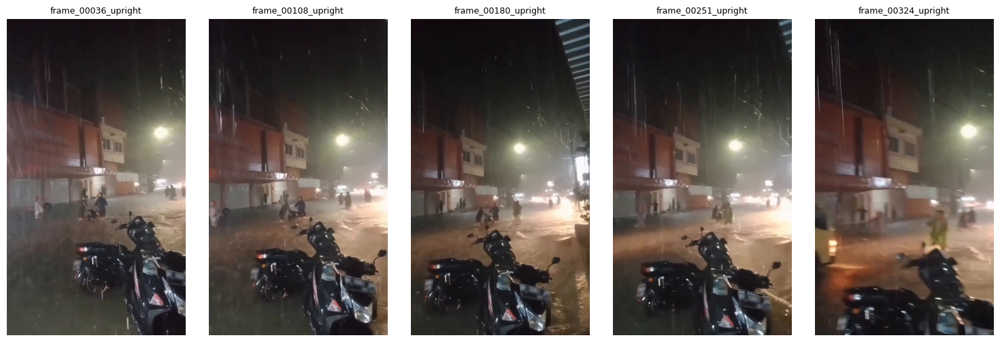

Corrected frames reviewed: 5


In [96]:
import cv2
import matplotlib.pyplot as plt

corrected_frames = sorted(
    evaluation_dir.glob("2023020108_frame_*_upright.jpg")
)

fig, axes = plt.subplots(1, 5, figsize=(15, 5))

for ax, frame_path in zip(axes, corrected_frames):
    frame = cv2.imread(str(frame_path))

    if frame is not None:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ax.imshow(frame_rgb)

    ax.set_title(frame_path.stem.replace("2023020108_", ""), fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Corrected frames reviewed:", len(corrected_frames))

Total evaluation frames: 25


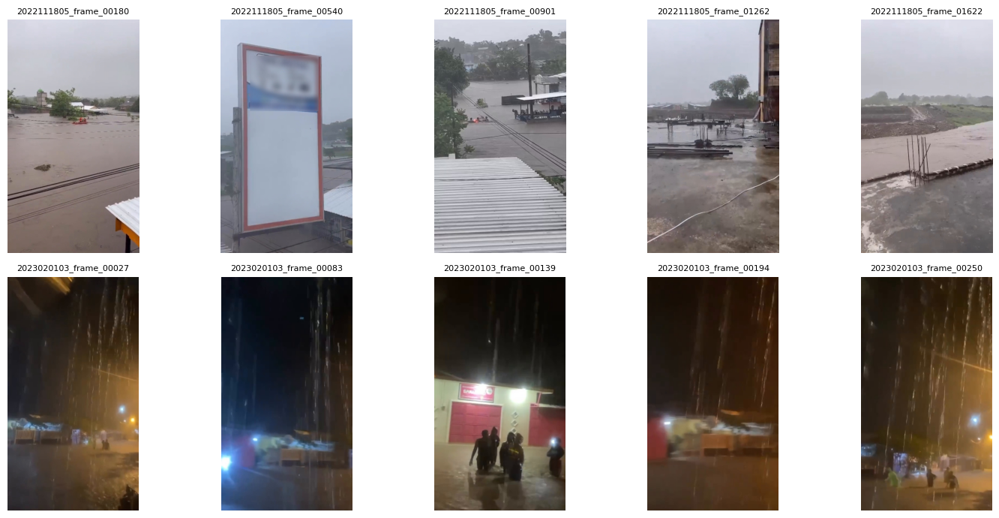

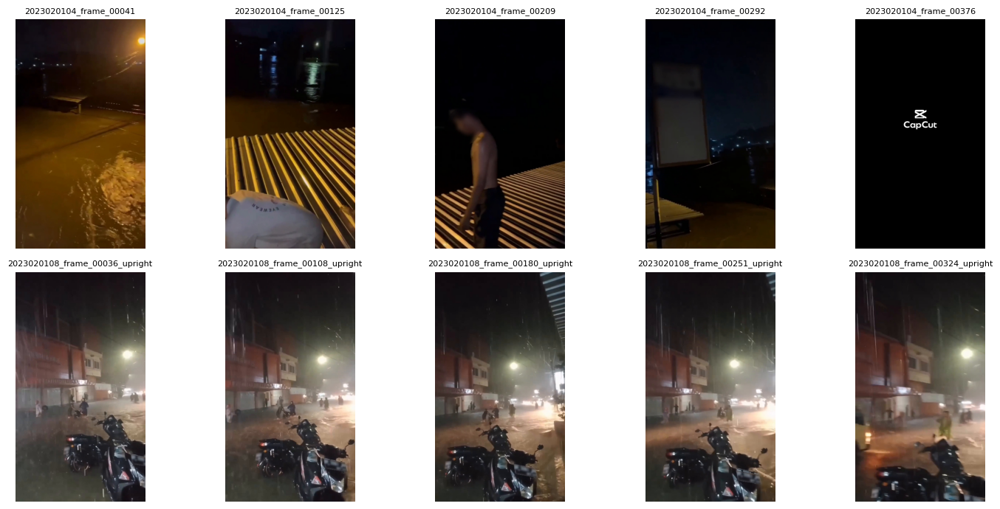

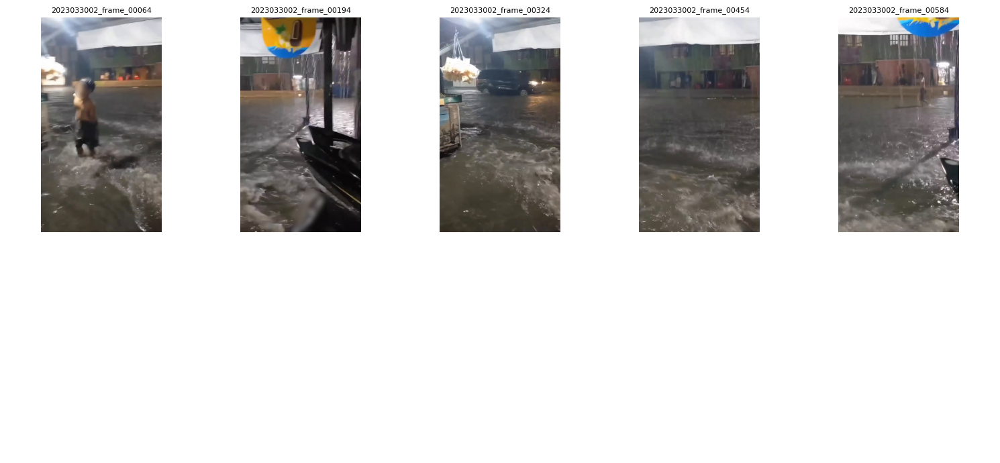

In [97]:
import cv2
import matplotlib.pyplot as plt

# Select 25 unique evaluation frames
evaluation_frames = sorted([
    p for p in evaluation_dir.glob("*.jpg")
    if not (
        p.name.startswith("2023020108_")
        and not p.stem.endswith("_upright")
    )
])

print("Total evaluation frames:", len(evaluation_frames))

# Display in smaller groups for easier inspection
for start in range(0, len(evaluation_frames), 10):

    batch = evaluation_frames[start:start + 10]

    fig, axes = plt.subplots(2, 5, figsize=(15, 7))
    axes = axes.flatten()

    for ax, frame_path in zip(axes, batch):
        frame = cv2.imread(str(frame_path))

        if frame is not None:
            ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

        ax.set_title(frame_path.stem, fontsize=8)
        ax.axis("off")

    for ax in axes[len(batch):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [98]:
import pandas as pd

evaluation_manifest = pd.DataFrame({
    "image_name": [p.name for p in evaluation_frames],
    "source_video": [
        p.name.split("_frame_")[0] + ".mp4"
        for p in evaluation_frames
    ],
    "usable": "pending_review",
    "people_present": "pending_review",
    "annotation_status": "not_started"
})

manifest_path = evaluation_dir / "evaluation_manifest.csv"

evaluation_manifest.to_csv(manifest_path, index=False)

print("Manifest saved:", manifest_path)
print("Total images:", len(evaluation_manifest))

display(evaluation_manifest)

Manifest saved: /content/drive/MyDrive/Hacks/AI-NETRA/datasets/evaluation/evaluation_manifest.csv
Total images: 25


,image_name,source_video,usable,people_present,annotation_status
0,2022111805_frame_00180.jpg,2022111805.mp4,pending_review,pending_review,not_started
1,2022111805_frame_00540.jpg,2022111805.mp4,pending_review,pending_review,not_started
2,2022111805_frame_00901.jpg,2022111805.mp4,pending_review,pending_review,not_started
3,2022111805_frame_01262.jpg,2022111805.mp4,pending_review,pending_review,not_started
4,2022111805_frame_01622.jpg,2022111805.mp4,pending_review,pending_review,not_started
5,2023020103_frame_00027.jpg,2023020103.mp4,pending_review,pending_review,not_started
6,2023020103_frame_00083.jpg,2023020103.mp4,pending_review,pending_review,not_started
7,2023020103_frame_00139.jpg,2023020103.mp4,pending_review,pending_review,not_started
8,2023020103_frame_00194.jpg,2023020103.mp4,pending_review,pending_review,not_started
9,2023020103_frame_00250.jpg,2023020103.mp4,pending_review,pending_review,not_started


In [99]:
import pandas as pd
import cv2

manifest_path = evaluation_dir / "evaluation_manifest.csv"

manifest = pd.read_csv(manifest_path)

detection_counts = []

for image_name in manifest["image_name"]:

    image_path = evaluation_dir / image_name

    image = cv2.imread(str(image_path))

    if image is None:
        detection_counts.append(None)
        print(f"Could not read: {image_name}")
        continue

    result = model_small.predict(
        source=image,
        classes=[0],
        conf=0.10,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    detection_counts.append(len(result.boxes))

manifest["yolo_person_count"] = detection_counts

manifest.to_csv(manifest_path, index=False)

print("YOLO11s preliminary detection results:\n")

display(
    manifest[
        ["image_name", "yolo_person_count"]
    ]
)

print("\nImages with detections:",
      (manifest["yolo_person_count"] > 0).sum())

print("Images without detections:",
      (manifest["yolo_person_count"] == 0).sum())

YOLO11s preliminary detection results:



,image_name,yolo_person_count
0,2022111805_frame_00180.jpg,0
1,2022111805_frame_00540.jpg,0
2,2022111805_frame_00901.jpg,5
3,2022111805_frame_01262.jpg,0
4,2022111805_frame_01622.jpg,0
5,2023020103_frame_00027.jpg,1
6,2023020103_frame_00083.jpg,0
7,2023020103_frame_00139.jpg,7
8,2023020103_frame_00194.jpg,0
9,2023020103_frame_00250.jpg,5



Images with detections: 14
Images without detections: 11


In [100]:
import json
from datetime import datetime, timezone

checkpoint = {
    "project": "AI-NETRA",
    "last_completed_step": 134,
    "next_step": 135,
    "next_task": "Review detection counts and prepare manual annotations",
    "evaluation_manifest": "datasets/evaluation/evaluation_manifest.csv",
    "evaluation_images": 25,
    "model": "models/yolo11s.pt",
    "completed_experiments": [
        "EXP-001",
        "EXP-002",
        "EXP-003",
        "EXP-004",
        "EXP-005"
    ],
    "saved_at_utc": datetime.now(timezone.utc).isoformat()
}

checkpoint_path = PROJECT_ROOT / "checkpoints" / "progress.json"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

with open(checkpoint_path, "w", encoding="utf-8") as f:
    json.dump(checkpoint, f, indent=4)

print("Checkpoint saved:", checkpoint_path)
print("Last completed step:", checkpoint["last_completed_step"])
print("Next step:", checkpoint["next_step"])
print("Safe to disconnect Colab.")

Checkpoint saved: /content/drive/MyDrive/Hacks/AI-NETRA/checkpoints/progress.json
Last completed step: 134
Next step: 135
Safe to disconnect Colab.


In [102]:
import json
import re
from datetime import datetime, timezone
from pathlib import Path

checkpoint_dir = PROJECT_ROOT / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Identify existing versioned checkpoints
existing = list(checkpoint_dir.glob("progress_*.json"))

versions = []

for file in existing:
    match = re.fullmatch(r"progress_(\d+)\.json", file.name)
    if match:
        versions.append(int(match.group(1)))

next_version = max(versions, default=0) + 1

checkpoint = {
    "project": "AI-NETRA",
    "checkpoint_version": next_version,
    "last_completed_step": 134,
    "next_step": 135,
    "next_task": "Review detection results and prepare manual annotations",
    "evaluation_manifest": "datasets/evaluation/evaluation_manifest.csv",
    "evaluation_images": 25,
    "model": "models/yolo11s.pt",
    "completed_experiments": [
        "EXP-001", "EXP-002", "EXP-003",
        "EXP-004", "EXP-005"
    ],
    "saved_at_utc": datetime.now(timezone.utc).isoformat()
}

checkpoint_path = (
    checkpoint_dir / f"progress_{next_version:03d}.json"
)

# Exclusive creation prevents accidental overwrite
with open(checkpoint_path, "x", encoding="utf-8") as f:
    json.dump(checkpoint, f, indent=4)

print("✅ Versioned checkpoint saved:", checkpoint_path)
print("Version:", next_version)
print("Last completed step:", checkpoint["last_completed_step"])

print("\nAvailable restore points:")
for path in sorted(checkpoint_dir.glob("progress_*.json")):
    print(" -", path.name)

✅ Versioned checkpoint saved: /content/drive/MyDrive/Hacks/AI-NETRA/checkpoints/progress_001.json
Version: 1
Last completed step: 134

Available restore points:
 - progress_001.json
